# Verificação e Validação — Predição de Carga Alta (EVCOMX)

Segue a **Aula 07 do bootcamp** (Verificação e Validação de Modelos; slides citados como
"slide N") e fecha o caminho `EDA/ → feature_selection/ → selecao_algoritmos/ → analise_modelos/`.

A aula separa duas perguntas (slide 6):
- **Verificação:** o modelo foi construído e executado como especificado? (código, pipeline,
  rótulos, transformações, métricas, reprodução)
- **Validação:** o modelo resolve o problema em dados novos? (generalização, representatividade,
  mudanças no tempo, critérios de uso)

**Esta etapa não escolhe nada.** Algoritmo, features e limiares continuam os do
`selecao_algoritmos/modelo_final.json`. Muito do que a aula pede já foi feito nas etapas
anteriores (split temporal, pipeline, validação cruzada temporal, baselines, métricas); aqui isso
é **conferido automaticamente** e o que faltava é acrescentado.

| Pergunta da aula | Seção |
|---|---|
| Checklist técnico antes de confiar nos números (slide 8 + Guia de Modelagem §6.1) | 1 |
| Treino bom não garante desempenho futuro: o gap (slides 10 a 12) | 2 |
| O teste não é uma segunda validação (slides 15 e 29) | 3 |
| Validação cruzada: limites e cuidados (slide 27) | 4 |
| Os dados mudaram? Data drift e concept drift (slides 33 e 34) | 5 |
| Guia de Modelagem §6.2: walk-forward mensal, robustez a erros de pesagem, calibração | 5b a 5d |
| Critérios de aceitação e monitoramento (slides 34 e 35) | 6.1 e 6.2 |
| Guia de Modelagem §6.3 e §6.4: validação de domínio e de negócio | 6.3 e 6.4 |
| Registro do experimento (slide 30) | 7 |
| Conclusão (slides 37 e 38) | 8 |

**Rode antes**, em ordem: `EDA/transforma_dataset.py`, `feature_selection/feature_selection.py`,
`selecao_algoritmos/selecao_algoritmos.py` e `analise_modelos/analise_modelos.py`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
import hashlib
import platform
from importlib import metadata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import joblib
from scipy.stats import ks_2samp

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, roc_auc_score,
                             average_precision_score)

SEED = 42
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.6, "axes.axisbelow": True})
# mesma paleta das etapas anteriores
AZUL, VERMELHO, CINZA, LARANJA, VERDE = "#2b6cb0", "#c0392b", "#7f8c8d", "#dd8a2e", "#4a8c4a"

## 0. Ler os arquivos das etapas anteriores

- `feature_selection/dataset_features_completo.csv`: as 84 candidatas, `conjunto` (split 70/15/15
  temporal) e `carga_alta`;
- `selecao_algoritmos/modelo_final.json`, `previsoes_validacao_teste.csv`, `resultado_teste.csv`,
  `limiares_validacao.csv` e os dois `.joblib`;
- `analise_modelos/`: as comparações pareadas e os baselines, para o checklist;
- `original_dataset/VariavelResposta.csv`: os **rótulos brutos**, para conferir o alvo.

In [2]:
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "selecao_algoritmos").is_dir() and (p / "original_dataset").is_dir())
PASTA_FS = RAIZ / "feature_selection"
PASTA_SEL = RAIZ / "selecao_algoritmos"
PASTA_AN = RAIZ / "analise_modelos"
PASTA_SAIDA = RAIZ / "verificacao_validacao"
PASTA_GRAF = PASTA_SAIDA / "graficos"
PASTA_GRAF.mkdir(parents=True, exist_ok=True)

def br(x, casas=2):
    """Número no formato brasileiro, para títulos e legendas: 0.425 -> '0,42'."""
    return f"{x:.{casas}f}".replace(".", ",")

def salvar(nome):
    plt.tight_layout()
    plt.savefig(PASTA_GRAF / f"{nome}.png", dpi=130, bbox_inches="tight")
    plt.show()

for pasta, arqs in [(PASTA_SEL, ["modelo_final.json", "previsoes_validacao_teste.csv", "resultado_teste.csv",
                                 "limiares_validacao.csv", "modelo_final_planoA.joblib", "modelo_final_planoB.joblib"]),
                    (PASTA_AN, ["baselines_validacao.csv", "comparacao_pareada_validacao.csv",
                                "comparacao_pareada_teste.csv", "modelo_para_uso_no_teste.csv"])]:
    for arq in arqs:
        assert (pasta / arq).exists(), f"{pasta.name}/{arq} não existe: rode as etapas anteriores primeiro!"

info = json.loads((PASTA_SEL / "modelo_final.json").read_text(encoding="utf-8"))
COLS_A, COLS_B = info["plano_A"]["features"], info["plano_B"]["features"]
LIM_A, LIM_B = info["plano_A"]["limiares"], info["plano_B"]["limiares"]
CENARIOS = list(LIM_A)  # ["não deixar passar (F2)", "equilíbrio (F1)", "evitar alarme falso (F0,5)"]
CURTO = {c: c.split(" (")[0] for c in CENARIOS}

df = pd.read_csv(PASTA_FS / "dataset_features_completo.csv")
df["inicio"] = pd.to_datetime(df["inicio"], utc=True, format="ISO8601")
df = df.sort_values(["inicio", "cd_corrida", "nu_carregamento"]).reset_index(drop=True)
resp = pd.read_csv(RAIZ / "original_dataset" / "VariavelResposta.csv")

# rótulo bruto e duração da parada por cestão, direto do arquivo da EVCOMX
rot = pd.concat([
    resp[["cd_corrida", f"is_carga_alta_carregamento_{n}", f"qt_segundos_duracao_parada_carregamento_{n}"]]
        .set_axis(["cd_corrida", "y_bruto", "seg_parada"], axis=1).assign(nu_carregamento=float(n))
    for n in (1, 2)])
df = df.merge(rot, on=["cd_corrida", "nu_carregamento"], how="left", validate="one_to_one")

treino = df[df.conjunto == "treino"].reset_index(drop=True)
valid = df[df.conjunto == "validacao"].reset_index(drop=True)
teste = df[df.conjunto == "teste"].reset_index(drop=True)
y_tr, y_va, y_te = treino["carga_alta"], valid["carga_alta"], teste["carga_alta"]
yt_, yv_, yte_ = y_tr.to_numpy(), y_va.to_numpy(), y_te.to_numpy()

prev_sel = pd.read_csv(PASTA_SEL / "previsoes_validacao_teste.csv")
res_sel = pd.read_csv(PASTA_SEL / "resultado_teste.csv")
lim_sel = pd.read_csv(PASTA_SEL / "limiares_validacao.csv", float_precision="round_trip")   # sem perder o último dígito

def periodo(d):
    a, b = d["inicio"].min().tz_convert("America/Sao_Paulo"), d["inicio"].max().tz_convert("America/Sao_Paulo")
    return f"{a:%d/%m/%Y}–{b:%d/%m/%Y}"
pd.DataFrame({"cestões": [len(treino), len(valid), len(teste)],
              "corridas": [d.cd_corrida.nunique() for d in (treino, valid, teste)],
              "cargas altas": [y_tr.sum(), y_va.sum(), y_te.sum()],
              "taxa": [y_tr.mean(), y_va.mean(), y_te.mean()],
              "período": [periodo(treino), periodo(valid), periodo(teste)]},
             index=["treino", "validação", "teste"]).round(3)

,cestões,corridas,cargas altas,taxa,período
treino,2473,1259,392,0.159,14/08/2025–25/04/2026
validação,513,270,92,0.179,25/04/2026–27/06/2026
teste,515,270,75,0.146,24/06/2026–04/08/2026


### Os modelos, com as mesmas definições da seleção

Mesmas definições "de fábrica" da seção 5 de `selecao_algoritmos.py` (e da análise). A Random
Forest com as features finais é o **plano A**; com as mesmas sem o histórico, o **plano B**
(hiperparâmetros do plano B lidos do `modelo_final.json`).

In [3]:
def montar(modelo, escala=False):
    passos = [("vazios", SimpleImputer(strategy="median"))]
    if escala:
        passos.append(("escala", StandardScaler()))
    passos.append(("modelo", modelo))
    return Pipeline(passos)

def floresta(seed=SEED, folha=5):
    return montar(RandomForestClassifier(n_estimators=300, min_samples_leaf=folha,
                                         class_weight="balanced_subsample", n_jobs=-1, random_state=seed))

ALGOS = {
    "Regressão logística": montar(LogisticRegression(max_iter=2000, class_weight="balanced"), escala=True),
    "Árvore de decisão": montar(DecisionTreeClassifier(max_depth=4, min_samples_leaf=20,
                                                       class_weight="balanced", random_state=SEED)),
    "Random Forest": floresta(),
    "Gradient Boosting": montar(GradientBoostingClassifier(learning_rate=0.05, n_estimators=200, max_depth=3,
                                                           subsample=0.8, random_state=SEED)),
}
COR = {"Regressão logística": LARANJA, "Árvore de decisão": VERDE, "Random Forest": AZUL,
       "Gradient Boosting": VERMELHO, "Random Forest (plano B)": "#6b8fb8"}

hp = info["plano_A"]["hiperparametros"]
assert info["plano_A"]["algoritmo"] == "Random Forest" and hp["n_estimators"] == 300 and hp["min_samples_leaf"] == 5, \
    "O modelo escolhido na seleção mudou: atualize ALGOS antes de seguir."

def pr(y, p):
    return average_precision_score(y, p)

def dobras_temporais(dados, n_blocos=6):   # idêntica à da seleção e da análise
    ordem = dados.groupby("cd_corrida")["inicio"].min().sort_values()
    bloco_corrida = pd.Series(np.arange(len(ordem)) * n_blocos // len(ordem), index=ordem.index)
    bloco = dados["cd_corrida"].map(bloco_corrida).to_numpy()
    return [(np.where(bloco <= k)[0], np.where(bloco == k + 1)[0]) for k in range(n_blocos - 1)]

CV = dobras_temporais(treino)

def notas_cv(modelo, cols, dobras=CV, dados=treino):
    """PR-AUC e ROC-AUC em cada prova de uma validação cruzada (treina e mede só dentro do treino)."""
    y = dados["carga_alta"].to_numpy()
    prs, rocs = [], []
    for a, b in dobras:
        p = clone(modelo).fit(dados.iloc[a][cols], y[a]).predict_proba(dados.iloc[b][cols])[:, 1]
        prs.append(pr(y[b], p)); rocs.append(roc_auc_score(y[b], p))
    return np.array(prs), np.array(rocs)

## 1. Checklist técnico antes de confiar nos números (slide 8)

As seis perguntas do slide 8, cada uma respondida por uma **conferência automática**. Se alguma
etapa anterior mudar (por exemplo, depois da pergunta 2 do e-mail à EVCOMX), basta rodar de novo:
o que quebrar aparece aqui.

Cada conferência vira uma linha da tabela `checklist_verificacao.csv`:
- **OK**: conferido, sem problema;
- **ATENÇÃO**: conferido, funciona, mas tem uma ressalva que precisa ir para a apresentação;
- **FALHOU**: o número das etapas anteriores não é confiável. As falhas graves também param o
  script (`assert`).

In [4]:
CHECK = []
def conferir(item, pergunta, como, resultado, detalhe=""):
    status = {True: "OK", False: "FALHOU"}.get(resultado, resultado)
    CHECK.append({"item": item, "pergunta (slide 8)": pergunta, "como conferimos": como,
                  "resultado": status, "detalhe": detalhe})
    print(f"[{status:7s}] {item} {como}" + (f"\n          {detalhe}" if detalhe else ""))

### 1.1 Os rótulos e as classes estão corretos?

O alvo `carga_alta` do dataset de modelagem passou por três etapas de código. Comparamos com o
arquivo **bruto** da EVCOMX, cestão a cestão.

In [5]:
P1 = "Os rótulos e as classes estão corretos?"
assert df["y_bruto"].notna().all(), "Há cestões sem rótulo no VariavelResposta.csv"
igual = (df["y_bruto"] == df["carga_alta"]).all()
assert igual, "O alvo do dataset de modelagem não bate com o VariavelResposta.csv"
conferir("1.1a", P1, "alvo do dataset = rótulo bruto do VariavelResposta.csv, cestão a cestão", igual,
         f"{len(df)} cestões conferidos; {int(df.carga_alta.sum())} cargas altas")

ou = (resp["is_carga_alta_carregamento_1"].astype(bool) | resp["is_carga_alta_carregamento_2"].astype(bool))
ok = (ou == resp["is_carga_alta"].astype(bool)).all()
conferir("1.1b", P1, "carga alta da corrida = carga alta no cestão 1 OU no cestão 2", ok,
         "é a coluna usada no histórico (taxa_ca_ult5/10)")

ok = set(df["carga_alta"].unique()) <= {0, 1}
conferir("1.1c", P1, "o alvo só tem 0 e 1 (1 = carga alta = classe positiva)", ok)

ok = ((df["seg_parada"] > 0) == (df["carga_alta"] == 1)).all()
conferir("1.1d", P1, "duração de parada > 0 se, e só se, houve carga alta", ok,
         "confirma que a duração (usada na análise para traduzir em minutos) é coerente com o rótulo")

[OK     ] 1.1a alvo do dataset = rótulo bruto do VariavelResposta.csv, cestão a cestão
          3501 cestões conferidos; 559 cargas altas
[OK     ] 1.1b carga alta da corrida = carga alta no cestão 1 OU no cestão 2
          é a coluna usada no histórico (taxa_ca_ult5/10)
[OK     ] 1.1c o alvo só tem 0 e 1 (1 = carga alta = classe positiva)
[OK     ] 1.1d duração de parada > 0 se, e só se, houve carga alta
          confirma que a duração (usada na análise para traduzir em minutos) é coerente com o rótulo


### 1.2 Treino, validação e teste passaram pelo mesmo pipeline?

Re-treinamos o plano A e o plano B **só no treino**, com as definições da seleção, e conferimos
que as chances são idênticas às de `previsoes_validacao_teste.csv`. Se forem, o mesmo pipeline
(mesmo preenchimento de vazios, mesmas features, mesma ordem de colunas) gerou validação e teste.

In [6]:
P2 = "Treino e teste passaram pelo mesmo pipeline?"
modelos = {nome: clone(m).fit(treino[COLS_A], y_tr) for nome, m in ALGOS.items()}
# o plano B pode ter saído "de fábrica" ou "ajustado" na seleção: usa os hiperparâmetros do .json
assert info["plano_B"]["algoritmo"] == "Random Forest", "O plano B mudou de algoritmo: atualize esta célula."
HP_B = {f"modelo__{k}": v for k, v in info["plano_B"]["hiperparametros"].items()}
modelo_B = clone(ALGOS["Random Forest"]).set_params(**HP_B).fit(treino[COLS_B], y_tr)
p_va = {nome: m.predict_proba(valid[COLS_A])[:, 1] for nome, m in modelos.items()}
p_va_A, p_te_A = p_va["Random Forest"], modelos["Random Forest"].predict_proba(teste[COLS_A])[:, 1]
p_va_B, p_te_B = modelo_B.predict_proba(valid[COLS_B])[:, 1], modelo_B.predict_proba(teste[COLS_B])[:, 1]

ok = True
for nome_conj, base, pa, pb in [("validacao", valid, p_va_A, p_va_B), ("teste", teste, p_te_A, p_te_B)]:
    s = base[["cd_corrida", "nu_carregamento"]].assign(pa=pa, pb=pb).merge(
        prev_sel[prev_sel.conjunto == nome_conj], on=["cd_corrida", "nu_carregamento"], validate="one_to_one")
    ok &= len(s) == len(base) and np.allclose(s["pa"], s["prob_planoA"], atol=1e-9) \
          and np.allclose(s["pb"], s["prob_planoB"], atol=1e-9)
assert ok, "As chances não batem com a seleção: confira a versão do scikit-learn ou os CSVs."
conferir("1.2a", P2, "chances re-treinadas aqui = chances salvas pela seleção (validação e teste, planos A e B)", ok,
         f"{len(valid) + len(teste)} cestões × 2 planos, diferença máxima < 1e-9")

uso = {}
ok_cols, ok_hp = True, True
for plano, cols in [("A", COLS_A), ("B", COLS_B)]:
    m = joblib.load(PASTA_SEL / f"modelo_final_plano{plano}.joblib")
    ok_cols &= list(m.feature_names_in_) == cols and list(m.named_steps) == ["vazios", "modelo"]
    par = m.named_steps["modelo"].get_params()
    ok_hp &= all(par[k] == v for k, v in info[f"plano_{plano}"]["hiperparametros"].items())
    uso[plano] = m
assert ok_cols and ok_hp, "Os .joblib não correspondem ao modelo_final.json"
conferir("1.2b", P2, "os .joblib para uso têm as features, a ordem e os hiperparâmetros do modelo_final.json",
         ok_cols and ok_hp)

nulos = pd.DataFrame({c: [d[c].isna().sum() for d in (treino, valid, teste)] for c in COLS_A},
                     index=["treino", "validação", "teste"])
so_hist = nulos.loc[:, nulos.sum() > 0].columns.str.startswith("taxa_ca_ult").all()
fora_treino = int(nulos.loc[["validação", "teste"]].to_numpy().sum())
conferir("1.2c", P2, f"vazios nas {len(COLS_A)} features: onde estão e como são tratados",
         "OK" if so_hist and fora_treino == 0 else "ATENÇÃO",
         f"só {nulos.sum()[nulos.sum() > 0].to_dict()} (a 1ª corrida não tem histórico); "
         f"{fora_treino} vazios na validação e no teste. O preenchimento é a mediana do treino, dentro do pipeline")

[OK     ] 1.2a chances re-treinadas aqui = chances salvas pela seleção (validação e teste, planos A e B)
          1028 cestões × 2 planos, diferença máxima < 1e-9
[OK     ] 1.2b os .joblib para uso têm as features, a ordem e os hiperparâmetros do modelo_final.json
[OK     ] 1.2c vazios nas 6 features: onde estão e como são tratados
          só {'taxa_ca_ult5': 2, 'taxa_ca_ult10': 2} (a 1ª corrida não tem histórico); 0 vazios na validação e no teste. O preenchimento é a mediana do treino, dentro do pipeline


### 1.3 As transformações foram ajustadas apenas no treino?

É a prevenção de vazamento do slide 21: dividir, ajustar só no treino, aplicar nas outras
partições sem reajustar. Conferimos **dentro dos modelos treinados** o que eles aprenderam:
a mediana usada para preencher vazios e a média/desvio da padronização da logística. Também
conferimos o próprio split: corridas inteiras, em ordem de tempo.

In [7]:
P3 = "As transformações foram ajustadas apenas no treino?"
med_tr = treino[COLS_A].median()
med_todos = df[COLS_A].median()
imp = modelos["Random Forest"].named_steps["vazios"].statistics_
ok = np.allclose(imp, med_tr)
assert ok
n_dif = int((~np.isclose(med_tr, med_todos)).sum())
conferir("1.3a", P3, "mediana de preenchimento do modelo = mediana do treino (não de todos os dados)", ok,
         f"em {n_dif} das {len(COLS_A)} features a mediana de todos os dados seria diferente: a conferência distingue os dois casos")

esc = modelos["Regressão logística"].named_steps["escala"]
X_imp = treino[COLS_A].fillna(med_tr)
ok = np.allclose(esc.mean_, X_imp.mean()) and np.allclose(esc.scale_, X_imp.std(ddof=0))
assert ok
conferir("1.3b", P3, "média e desvio da padronização (logística) = os do treino", ok)

tv = pd.concat([treino, valid])
ok = np.allclose(uso["A"].named_steps["vazios"].statistics_, tv[COLS_A].median())
conferir("1.3c", P3, "o modelo para uso (.joblib) preenche vazios com a mediana de treino + validação", ok,
         "é o esperado: ele foi re-treinado em treino + validação; o teste continua fora")

conferir("1.3d", P3, "seleção de features só no treino (leitura do código)", "ATENÇÃO",
         "feature_selection.py: filtro, VIF, L1, Elastic Net, RFE, Boruta e o filtro de materiais (>= 5% dos cestões) "
         "rodam no treino. Mas a importância por permutação (1 dos 6 votos, §7) é medida na VALIDAÇÃO, e a validação "
         "também escolheu quantas features ficam (§10). Não vaza para o teste, mas deixa a nota da validação otimista (seção 3)")

conj_corr = df.groupby("cd_corrida")["conjunto"].nunique()
ok = (conj_corr == 1).all()
assert ok, "Há corridas com cestões em partições diferentes"
conferir("1.3e", P3, "os dois cestões de cada corrida ficam na mesma partição (slide 17: dados agrupados)", ok,
         f"{len(conj_corr)} corridas conferidas")

ini_corr = df.groupby("cd_corrida")["inicio"].min()
part_corr = df.groupby("cd_corrida")["conjunto"].first()
lim = {c: (ini_corr[part_corr == c].min(), ini_corr[part_corr == c].max()) for c in ["treino", "validacao", "teste"]}
ok = lim["treino"][1] < lim["validacao"][0] and lim["validacao"][1] < lim["teste"][0]
assert ok, "O split não está em ordem de tempo por corrida"
qtd = part_corr.value_counts(normalize=True)
conferir("1.3f", P3, "em ordem de tempo: toda corrida do treino começa antes da 1ª da validação, e assim por diante",
         ok, f"corridas: treino {qtd['treino']:.1%}, validação {qtd['validacao']:.1%}, teste {qtd['teste']:.1%}")

# cestões (não corridas) que caem depois do início da partição seguinte
cruza = pd.concat([treino[treino.inicio >= valid.inicio.min()], valid[valid.inicio >= teste.inicio.min()]])
w = df.pivot_table(index="cd_corrida", columns="nu_carregamento", values="inicio", aggfunc="first")
gap12 = (w[2.0] - w[1.0]).dt.total_seconds() / 60
conferir("1.3g", P3, "cestões que caem depois do início da partição seguinte",
         "OK" if len(cruza) == 0 else "ATENÇÃO",
         f"{len(cruza)} de {len(df)} cestões ({', '.join(cruza.cd_corrida + ' c' + cruza.nu_carregamento.astype(int).astype(str))}): "
         f"o cestão 2 dessas corridas tem hora registrada bem depois do cestão 1. Efeito desprezível, mas mostra "
         f"um problema de dado: {int((gap12 < 0).sum())} corridas com o cestão 2 antes do 1 e {int((gap12 > 1440).sum())} "
         f"com mais de 1 dia entre eles (mediana: {gap12.median():.0f} min)")

[OK     ] 1.3a mediana de preenchimento do modelo = mediana do treino (não de todos os dados)
          em 3 das 6 features a mediana de todos os dados seria diferente: a conferência distingue os dois casos
[OK     ] 1.3b média e desvio da padronização (logística) = os do treino
[OK     ] 1.3c o modelo para uso (.joblib) preenche vazios com a mediana de treino + validação
          é o esperado: ele foi re-treinado em treino + validação; o teste continua fora
[ATENÇÃO] 1.3d seleção de features só no treino (leitura do código)
          feature_selection.py: filtro, VIF, L1, Elastic Net, RFE, Boruta e o filtro de materiais (>= 5% dos cestões) rodam no treino. Mas a importância por permutação (1 dos 6 votos, §7) é medida na VALIDAÇÃO, e a validação também escolheu quantas features ficam (§10). Não vaza para o teste, mas deixa a nota da validação otimista (seção 3)
[OK     ] 1.3e os dois cestões de cada corrida ficam na mesma partição (slide 17: dados agrupados)
          1799 corridas co

### 1.4 Há vazamento de dados? (slides 19 e 20)

Os três tipos de vazamento do slide 20:
1. **Variável pós-evento:** nenhuma feature pode existir só depois da carga alta.
2. **Pré-processamento global:** conferido na 1.3.
3. **Duplicatas ou grupos:** registros repetidos ou da mesma corrida dos dois lados do split.

O ponto mais delicado do projeto é o **histórico** (`taxa_ca_ult5/10`): ele usa o rótulo das
corridas anteriores. Conferimos que ele não usa a corrida atual (`shift(1)`), mostramos o que
aconteceria **se usasse** (vazamento de verdade) e medimos quanto o modelo perde se o resultado
da corrida imediatamente anterior **não** estiver disponível na hora de prever (a pergunta ainda
não feita à EVCOMX). Isso só usa o treino (CV) e a validação: o teste fica de fora.

In [8]:
P4 = "Há vazamento de dados?"
PROIBIDAS = {"carga_alta", "y_bruto", "seg_parada", "carga_alta_c1", "inicio", "cd_corrida", "nu_carregamento",
             "conjunto"}
usadas = set(COLS_A) | set(COLS_B)
ok = not (usadas & PROIBIDAS) and not any(c.startswith(("qt_", "is_")) for c in usadas)
assert ok, f"Feature proibida no modelo: {usadas & PROIBIDAS}"
conferir("1.4a", P4, "nenhuma feature é pós-evento, identificador ou data (slide 20)", ok,
         "fora do modelo: duração da parada, carga_alta_c1 (depende do timing), início, corrida, carregamento")

def historico(lag):
    """Taxa de carga alta das últimas N corridas, em ordem de início. lag=1 é o do projeto (exclui a
    corrida atual); lag=0 inclui a atual (vazamento); lag=2 pula também a corrida anterior."""
    h = resp[["cd_corrida", "is_carga_alta"]].assign(t=resp["cd_corrida"].map(ini_corr)).sort_values("t")
    assert h["t"].notna().all()
    return pd.DataFrame({f"taxa_ca_ult{n}": h["is_carga_alta"].shift(lag).rolling(n, min_periods=1).mean().to_numpy()
                         for n in (5, 10)}, index=h["cd_corrida"].to_numpy())

h1 = historico(1)
ok = all(np.allclose(df[c].to_numpy(), df["cd_corrida"].map(h1[c]).to_numpy(), equal_nan=True)
         for c in ["taxa_ca_ult5", "taxa_ca_ult10"])
assert ok, "O histórico do dataset não é o histórico com shift(1): possível vazamento"
conferir("1.4b", P4, "taxa_ca_ult5/10 recalculadas do arquivo bruto com shift(1) = as do dataset", ok,
         "o histórico de cada corrida só usa corridas que começaram antes dela")

def com_historico(base, lag):
    h = historico(lag)
    out = base.copy()
    for c in ["taxa_ca_ult5", "taxa_ca_ult10"]:
        out[c] = out["cd_corrida"].map(h[c])
    return out

linhas = []
for lag, nome in [(0, "inclui a corrida atual (VAZAMENTO, só para mostrar)"),
                  (1, "corridas anteriores (o do projeto)"),
                  (2, "pula a corrida anterior")]:
    tr_l, va_l = com_historico(treino, lag), com_historico(valid, lag)
    cv_pr, _ = notas_cv(floresta(), COLS_A, dados=tr_l)
    linha = {"histórico": nome, "lag": lag, "CV temporal PR-AUC": cv_pr.mean(), "CV dp": cv_pr.std()}
    if lag > 0:   # a versão com vazamento não é medida na validação: não há o que decidir com ela
        p = floresta().fit(tr_l[COLS_A], y_tr).predict_proba(va_l[COLS_A])[:, 1]
        linha["validação PR-AUC"] = pr(yv_, p)
    linhas.append(linha)
tab_lag = pd.DataFrame(linhas).set_index("histórico")
print(f"Random Forest, {len(COLS_A)} features, mudando só o histórico:")
print(tab_lag.round(3).to_string(), "\n")

v1, v2 = tab_lag["validação PR-AUC"].iloc[1], tab_lag["validação PR-AUC"].iloc[2]
gap_corr = ini_corr.sort_values().diff().dt.total_seconds().div(60)
conferir("1.4c", P4, "sensibilidade ao timing do histórico (pergunta ainda não feita à EVCOMX)", "ATENÇÃO",
         f"com vazamento a CV iria de {br(tab_lag['CV temporal PR-AUC'].iloc[1])} para "
         f"{br(tab_lag['CV temporal PR-AUC'].iloc[0])}; pulando a corrida anterior, a validação vai de {br(v1)} para "
         f"{br(v2)}. Entre o início de corridas seguidas passam {gap_corr.median():.0f} min (mediana). "
         f"Só a EVCOMX sabe se o resultado da corrida anterior já é conhecido quando o cestão é montado")

ok = not df.duplicated(["cd_corrida", "nu_carregamento"]).any()
assert ok
feat80 = [c for c in df.columns if c not in PROIBIDAS | {"carga_alta_c1"}]
dup = df[df.duplicated(feat80, keep=False)]
dup_cruz = dup.groupby(feat80, dropna=False)["conjunto"].nunique().gt(1).sum() if len(dup) else 0
conferir("1.4d", P4, "duplicatas: cada cestão aparece uma vez; nenhuma linha de features repetida entre partições",
         ok and dup_cruz == 0, f"{len(dup)} linhas com as {len(feat80)} colunas de features idênticas a outra; {dup_cruz} grupos cruzando partições")

conferir("1.4e", P4, "a data/hora não é feature (com split temporal, ela só ensinaria 'em que época estamos')",
         "inicio" not in usadas)

[OK     ] 1.4a nenhuma feature é pós-evento, identificador ou data (slide 20)
          fora do modelo: duração da parada, carga_alta_c1 (depende do timing), início, corrida, carregamento
[OK     ] 1.4b taxa_ca_ult5/10 recalculadas do arquivo bruto com shift(1) = as do dataset
          o histórico de cada corrida só usa corridas que começaram antes dela
Random Forest, 6 features, mudando só o histórico:
                                                     lag  CV temporal PR-AUC  CV dp  validação PR-AUC
histórico                                                                                            
inclui a corrida atual (VAZAMENTO, só para mostrar)    0               0.498  0.105               NaN
corridas anteriores (o do projeto)                     1               0.413  0.109             0.427
pula a corrida anterior                                2               0.394  0.094             0.403 

[ATENÇÃO] 1.4c sensibilidade ao timing do histórico (pergunta ainda não feita à 

### 1.5 As métricas correspondem ao objetivo do problema?

A escolha da métrica foi justificada na análise (seção 2: PR-AUC, porque a classe é rara e o
corte vem depois). Aqui conferimos as **contas**: refazemos, a partir das chances salvas, os
números da conferência no teste (`resultado_teste.csv`) e conferimos que os limiares do
`modelo_final.json` são os da validação.

In [9]:
P5 = "As métricas correspondem ao objetivo do problema?"
ok, ok_lim, entre = True, True, 0
s = prev_sel[prev_sel.conjunto != "treino"]
for plano, col, lims in [("A", "prob_planoA", LIM_A), ("B", "prob_planoB", LIM_B)]:
    st = s[s.conjunto == "teste"]
    y, p = st["carga_alta"].to_numpy(), st[col].to_numpy()
    for cen, l in lims.items():
        r = res_sel[res_sel.plano.str.startswith(plano) & (res_sel.cenario == cen)].iloc[0]
        prev = p >= l
        vp = (prev & (y == 1)).sum()   # matriz de confusão feita à mão: a classe positiva é a carga alta
        ok &= np.isclose(vp / (y == 1).sum(), r["recall"]) and np.isclose(vp / prev.sum(), r["precisao"]) \
              and np.isclose(100 * prev.mean(), r["alarmes_por_100"]) and np.isclose(accuracy_score(y, prev), r["acuracia"]) \
              and np.isclose(pr(y, p), r["PR-AUC"]) and np.isclose(roc_auc_score(y, p), r["ROC-AUC"], atol=5e-4)
        # o modelo_final.json e o limiares_validacao.csv guardam o limiar sem arredondar: têm de ser iguais
        exato = lim_sel[(lim_sel.plano == plano) & (lim_sel.cenario == cen)]["limiar"].iloc[0]
        ok_lim &= abs(exato - l) < 5e-5
        m = (s[col] >= min(l, exato)) & (s[col] < max(l, exato)) & (abs(l - exato) > 1e-12)
        entre += int(m.sum())
        if m.any():
            print(f"  plano {plano}, {CURTO[cen]}: limiar exato {exato:.6f}, no .json {l}; cestões no meio:",
                  ", ".join(f"{r.cd_corrida} c{int(r.nu_carregamento)} ({r.conjunto})" for r in s[m].itertuples()))
assert ok and ok_lim, "Os números de resultado_teste.csv ou os limiares não batem com as chances salvas"
conferir("1.5a", P5, "recall, precisão, alarmes, acurácia, PR-AUC e ROC-AUC do teste refeitos à mão = resultado_teste.csv",
         ok, "inclui a matriz de confusão montada à mão, com 'carga alta' como classe positiva")
conferir("1.5b", P5, "limiares do modelo_final.json = os escolhidos na validação (limiares_validacao.csv)",
         "OK" if entre == 0 else "ATENÇÃO",
         "o .json guarda os limiares sem arredondar (corrigido na seleção): nenhum cestão muda de lado"
         if entre == 0 else
         f"o .json arredonda o limiar. {entre} cestões têm chance entre o limiar arredondado e o exato e "
         "deixariam de dar alarme. Salvar o limiar sem arredondar")

media_ca, media_n = p_va_A[yv_ == 1].mean(), p_va_A[yv_ == 0].mean()
conferir("1.5c", P5, "as chances apontam para o lado certo (maior nas cargas altas que nos normais)", media_ca > media_n,
         f"validação: chance média {br(media_ca)} nas cargas altas contra {br(media_n)} nos normais")

base_maioria = 1 - yv_.mean()
conferir("1.5d", P5, "a métrica principal não é a acurácia", "OK",
         f"quem sempre diz 'normal' tem {base_maioria:.0%} de acurácia na validação e recall zero; a PR-AUC "
         "foi escolhida antes de comparar modelos (análise, seção 2)")

[OK     ] 1.5a recall, precisão, alarmes, acurácia, PR-AUC e ROC-AUC do teste refeitos à mão = resultado_teste.csv
          inclui a matriz de confusão montada à mão, com 'carga alta' como classe positiva
[OK     ] 1.5b limiares do modelo_final.json = os escolhidos na validação (limiares_validacao.csv)
          o .json guarda os limiares sem arredondar (corrigido na seleção): nenhum cestão muda de lado
[OK     ] 1.5c as chances apontam para o lado certo (maior nas cargas altas que nos normais)
          validação: chance média 0,57 nas cargas altas contra 0,38 nos normais
[OK     ] 1.5d a métrica principal não é a acurácia
          quem sempre diz 'normal' tem 82% de acurácia na validação e recall zero; a PR-AUC foi escolhida antes de comparar modelos (análise, seção 2)


### 1.6 O experimento pode ser reproduzido?

Duas perguntas:
- Com a mesma semente, o resultado é **idêntico**? (é o que permite as conferências acima)
- Com **outra** semente, quanto a nota muda? A Random Forest sorteia linhas e colunas; se a nota
  variar muito só pela semente, diferenças pequenas entre modelos não querem dizer nada.

As sementes só mudam o sorteio interno da floresta; o modelo continua o mesmo. Medimos na
validação, que já foi usada para escolher: nada aqui escolhe de novo.

In [10]:
P6 = "O experimento pode ser reproduzido?"
p_rep = floresta().fit(treino[COLS_A], y_tr).predict_proba(valid[COLS_A])[:, 1]
dif_rep = np.abs(p_rep - p_va_A).max()
ok = dif_rep < 1e-12
assert ok
conferir("1.6a", P6, "treinar duas vezes com a mesma semente dá as mesmas chances", ok,
         f"diferença máxima {dif_rep:.0e}: é só a ordem da soma entre os núcleos do processador (n_jobs=-1), "
         "não muda nenhum alarme")

SEMENTES = range(20)
pr_seed = np.array([pr(yv_, floresta(seed=s).fit(treino[COLS_A], y_tr).predict_proba(valid[COLS_A])[:, 1])
                    for s in SEMENTES])
pr_gb = pr(yv_, p_va["Gradient Boosting"])
conferir("1.6b", P6, f"variação só pela semente ({len(SEMENTES)} sementes, validação)", "OK",
         f"PR-AUC da Random Forest de {br(pr_seed.min(), 3)} a {br(pr_seed.max(), 3)} (média {br(pr_seed.mean(), 3)}, "
         f"dp {br(pr_seed.std(), 3)}); semente 42 = {br(pr(yv_, p_va_A), 3)}. Gradient Boosting = {br(pr_gb, 3)}")

conferir("1.6c", P6, "registro do experimento (dados, partições, modelo, avaliação, ambiente)", "OK",
         "gerado na seção 7: registro_experimento.json e requirements_rodada.txt, com o hash de cada arquivo de dados")

[OK     ] 1.6a treinar duas vezes com a mesma semente dá as mesmas chances
          diferença máxima 2e-16: é só a ordem da soma entre os núcleos do processador (n_jobs=-1), não muda nenhum alarme
[OK     ] 1.6b variação só pela semente (20 sementes, validação)
          PR-AUC da Random Forest de 0,411 a 0,427 (média 0,421, dp 0,004); semente 42 = 0,427. Gradient Boosting = 0,395
[OK     ] 1.6c registro do experimento (dados, partições, modelo, avaliação, ambiente)
          gerado na seção 7: registro_experimento.json e requirements_rodada.txt, com o hash de cada arquivo de dados


### 1.7 Os resultados são coerentes com uma baseline? (slide 31)

As baselines já foram medidas na análise. Aqui só lemos os vereditos para o checklist.

In [11]:
P7 = "Os resultados são coerentes com uma baseline?"
cp_va = pd.read_csv(PASTA_AN / "comparacao_pareada_validacao.csv")
cp_te = pd.read_csv(PASTA_AN / "comparacao_pareada_teste.csv")
REGRA = "Regra: mais taxa_ca_ult5 (só histórico)"
def leitura(tab, met):
    return tab[(tab.iloc[:, 0] == REGRA) & (tab["métrica"] == met)]["leitura"].iloc[0]

ok = pr(yv_, p_va_A) > yv_.mean() and pr(yte_, p_te_A) > yte_.mean()
conferir("1.7a", P7, "a Random Forest supera o chute (maioria) na validação e no teste", ok,
         f"PR-AUC {br(pr(yv_, p_va_A))} × {br(yv_.mean())} na validação; {br(pr(yte_, p_te_A))} × {br(yte_.mean())} no teste")
conferir("1.7b", P7, "a Random Forest contra a regra só do histórico (bootstrap pareado da análise)", "ATENÇÃO",
         f"validação: PR-AUC {leitura(cp_va, 'PR-AUC')}, recall 20/100 {leitura(cp_va, 'recall 20/100')}; "
         f"teste: PR-AUC {leitura(cp_te, 'PR-AUC')}, recall 20/100 {leitura(cp_te, 'recall 20/100')}. "
         "A régua da apresentação é a regra do histórico, não só o chute")

[OK     ] 1.7a a Random Forest supera o chute (maioria) na validação e no teste
          PR-AUC 0,43 × 0,18 na validação; 0,39 × 0,15 no teste
[ATENÇÃO] 1.7b a Random Forest contra a regra só do histórico (bootstrap pareado da análise)
          validação: PR-AUC vantagem real, recall 20/100 empate; teste: PR-AUC empate, recall 20/100 desvantagem real. A régua da apresentação é a regra do histórico, não só o chute


### 1.8 Verificação técnica do Guia de Modelagem (§6.1)

O Guia de Modelagem pede três conferências que o slide 8 não cobre explicitamente:
- **teste de sanidade com o alvo embaralhado** (*label shuffling*): se embaralharmos a carga alta
  do treino, o modelo não tem o que aprender e a nota deve cair ao nível do acaso. Se não cair, há
  vazamento ou erro no pipeline;
- **testes unitários da agregação**: peso total depois de agregar = soma das camadas;
  proporções somam 1; volume > 0; densidade = peso ÷ volume;
- **consistência dos joins**: as contagens de corridas e cestões batem em cada etapa?

A auditoria de vazamento (1.4), a reprodutibilidade (1.6) e a estabilidade por prova e por
semente (1.6b e seção 2) já estão acima.

In [12]:
P8 = "Verificação técnica do Guia de Modelagem (§6.1)"
N_EMBARALHA = 10
pr_emb_va, pr_emb_cv = [], []
for i in range(N_EMBARALHA):
    rng_e = np.random.default_rng(SEED + i)
    y_emb = rng_e.permutation(yt_)
    m = clone(floresta()).fit(treino[COLS_A], y_emb)
    pr_emb_va.append(pr(yv_, m.predict_proba(valid[COLS_A])[:, 1]))
    if i < 3:   # a CV temporal com alvo embaralhado (3 repetições bastam)
        t_emb = treino.assign(carga_alta=y_emb)
        pr_emb_cv.append(notas_cv(floresta(), COLS_A, dados=t_emb)[0].mean())
pr_emb_va = np.array(pr_emb_va)
ok = (pr_emb_va.mean() < yv_.mean() + 0.05) and (pr(yv_, p_va_A) > pr_emb_va.max())
conferir("1.8a", P8, f"alvo do treino embaralhado ({N_EMBARALHA}×): a nota cai ao nível do acaso", ok,
         f"PR-AUC na validação com alvo embaralhado: média {br(pr_emb_va.mean())} (de {br(pr_emb_va.min())} a "
         f"{br(pr_emb_va.max())}), chute {br(yv_.mean())}, modelo real {br(pr(yv_, p_va_A))}; "
         f"CV temporal com alvo embaralhado {br(np.mean(pr_emb_cv))} (chute no treino {br(yt_.mean())})")

# testes unitários: refaz a agregação a partir das camadas limpas da EDA
base_eda = pd.read_csv(RAIZ / "EDA" / "base.csv", usecols=["cd_corrida", "nu_carregamento", "nu_camada", "peso_t",
                                                            "volume_m3", "tp_material", "cd_codigo_material"])
cam = base_eda[base_eda.nu_carregamento.isin([1, 2])]
soma = cam.groupby(["cd_corrida", "nu_carregamento"]).agg(peso=("peso_t", "sum"), vol=("volume_m3", "sum")).reset_index()
u = df.merge(soma, on=["cd_corrida", "nu_carregamento"], how="left")
dif_peso = (u["peso_t_total"] - u["peso"]).abs().max()
dif_vol = (u["volume_m3_total"] - u["vol"]).abs().max()
soma_classes = (df["prop_leve"] + df["prop_peso_misto"] + df["prop_peso_pesado"] - 1).abs().max()
cols_mat = [c for c in df.columns if c.startswith("prop_") and c not in
            ("prop_leve", "prop_peso_misto", "prop_peso_pesado", "prop_vol_leve", "prop_vol_misto", "prop_vol_pesado",
             "prop_leve_topo", "prop_leve_base")]
soma_mat = (df[cols_mat].sum(axis=1) - 1).abs().max()
vol_pos = (df["volume_m3_total"] > 0).all() and (cam["volume_m3"] > 0).all()
dif_dens = (df["densidade_media"] - df["peso_t_total"] / df["volume_m3_total"]).abs().max()
ok = max(dif_peso, dif_vol, soma_classes, soma_mat, dif_dens) < 1e-6 and vol_pos
conferir("1.8b", P8, "testes unitários da agregação (peso, volume, proporções, densidade)", ok,
         f"peso total = soma das camadas (dif. máx. {dif_peso:.1e} t); volume idem ({dif_vol:.1e} m³); "
         f"leve + misto + pesado = 1 ({soma_classes:.1e}); soma dos {len(cols_mat)} materiais = 1 ({soma_mat:.1e}); "
         f"volume > 0 em todas as camadas e cestões; densidade = peso ÷ volume ({dif_dens:.1e})")

# consistência dos joins: contagens por etapa
bruto = pd.read_csv(RAIZ / "original_dataset" / "infos_camadas.csv", usecols=["cd_corrida", "nu_carregamento"])
cont = pd.DataFrame([
    ("original_dataset/infos_camadas.csv (cestões 1 e 2)", bruto[bruto.nu_carregamento.isin([1, 2])]
         .drop_duplicates().shape[0], bruto.cd_corrida.nunique()),
    ("EDA/base.csv (limpa; cestões 1 e 2)", cam[["cd_corrida", "nu_carregamento"]].drop_duplicates().shape[0],
     cam.cd_corrida.nunique()),
    ("original_dataset/VariavelResposta.csv (2 cestões por corrida)", 2 * len(resp), resp.cd_corrida.nunique()),
    ("feature_selection/dataset_features_completo.csv", len(df), df.cd_corrida.nunique()),
], columns=["etapa", "cestões", "corridas"])
cont_ok = (cont.iloc[1]["cestões"] == cont.iloc[3]["cestões"]) and df["y_bruto"].notna().all()
print(cont.to_string(index=False))
conferir("1.8c", P8, "consistência dos joins: cestões da base limpa = cestões do dataset de modelagem, todos com rótulo",
         cont_ok, f"{cont.iloc[3]['cestões']} cestões em {cont.iloc[3]['corridas']} corridas; "
         f"{cont.iloc[0]['cestões'] - cont.iloc[1]['cestões']} cestões do bruto saem na limpeza da EDA "
         f"(só camadas abaixo de 2.000 kg, peso zero incluído); o VariavelResposta tem {cont.iloc[2]['cestões'] - cont.iloc[3]['cestões']} "
         "cestões sem nenhuma camada registrada (sem receita, não há o que prever)")

[OK     ] 1.8a alvo do treino embaralhado (10×): a nota cai ao nível do acaso
          PR-AUC na validação com alvo embaralhado: média 0,19 (de 0,16 a 0,23), chute 0,18, modelo real 0,43; CV temporal com alvo embaralhado 0,16 (chute no treino 0,16)
[OK     ] 1.8b testes unitários da agregação (peso, volume, proporções, densidade)
          peso total = soma das camadas (dif. máx. 1.4e-14 t); volume idem (1.4e-14 m³); leve + misto + pesado = 1 (4.4e-16); soma dos 18 materiais = 1 (7.8e-16); volume > 0 em todas as camadas e cestões; densidade = peso ÷ volume (4.4e-16)
                                                        etapa  cestões  corridas
           original_dataset/infos_camadas.csv (cestões 1 e 2)     3501      1799
                          EDA/base.csv (limpa; cestões 1 e 2)     3501      1799
original_dataset/VariavelResposta.csv (2 cestões por corrida)     3598      1799
              feature_selection/dataset_features_completo.csv     3501      1799
[OK     ] 1.8c consis

In [13]:
checklist = pd.DataFrame(CHECK).set_index("item")
assert not (checklist["resultado"] == "FALHOU").any(), checklist[checklist["resultado"] == "FALHOU"]
print(checklist["resultado"].value_counts().to_string())
checklist[["pergunta (slide 8)", "como conferimos", "resultado"]]

resultado
OK         27
ATENÇÃO     4


,pergunta (slide 8),como conferimos,resultado
item,,,
1.1a,Os rótulos e as classes estão corretos?,alvo do dataset = rótulo bruto do VariavelResp...,OK
1.1b,Os rótulos e as classes estão corretos?,carga alta da corrida = carga alta no cestão 1...,OK
1.1c,Os rótulos e as classes estão corretos?,o alvo só tem 0 e 1 (1 = carga alta = classe p...,OK
1.1d,Os rótulos e as classes estão corretos?,"duração de parada > 0 se, e só se, houve carga...",OK
1.2a,Treino e teste passaram pelo mesmo pipeline?,chances re-treinadas aqui = chances salvas pel...,OK
1.2b,Treino e teste passaram pelo mesmo pipeline?,"os .joblib para uso têm as features, a ordem e...",OK
1.2c,Treino e teste passaram pelo mesmo pipeline?,vazios nas 6 features: onde estão e como são t...,OK
1.3a,As transformações foram ajustadas apenas no tr...,mediana de preenchimento do modelo = mediana d...,OK
1.3b,As transformações foram ajustadas apenas no tr...,média e desvio da padronização (logística) = o...,OK


## 2. Treino bom não garante desempenho futuro: o gap (slides 10 a 12)

O slide 12 pede para olhar a **diferença** entre treino e teste. Medimos cada modelo em quatro
lugares, do mais "fácil" ao mais honesto:

| Onde | O que mede |
|---|---|
| **treino** (o modelo se avalia nos dados em que aprendeu) | quanto ele **decorou** |
| **CV temporal** (dentro do treino, sempre prevendo meses seguintes) | quanto ele generaliza **no regime antigo** |
| **validação** (abr–jun/2026) | quanto ele aguenta o **começo do regime novo**; foi onde escolhemos |
| **teste** (jun–ago/2026) | a nota final, que não escolheu nada |

O teste aparece só para o plano A e o plano B, cujas notas já foram publicadas. Os outros
algoritmos não são medidos no teste: não há motivo para olhar o teste com modelos que não vão
ser usados (slide 15).

In [14]:
linhas = []
cand = [(nome, modelos[nome], COLS_A) for nome in ALGOS] + [("Random Forest (plano B)", modelo_B, COLS_B)]
for nome, m, cols in cand:
    base_alg = ALGOS["Random Forest"] if nome.endswith("(plano B)") else ALGOS[nome]
    cv_pr, cv_roc = notas_cv(base_alg, cols)
    p_in = m.predict_proba(treino[cols])[:, 1]
    p_v = m.predict_proba(valid[cols])[:, 1]
    linha = {"modelo": nome, "treino": pr(yt_, p_in), "CV temporal": cv_pr.mean(), "CV dp": cv_pr.std(),
             "validação": pr(yv_, p_v), "teste": np.nan,
             "ROC treino": roc_auc_score(yt_, p_in), "ROC CV": cv_roc.mean(), "ROC validação": roc_auc_score(yv_, p_v),
             "ROC teste": np.nan}
    if nome == "Random Forest":
        linha["teste"], linha["ROC teste"] = pr(yte_, p_te_A), roc_auc_score(yte_, p_te_A)
    if nome.endswith("(plano B)"):
        linha["teste"], linha["ROC teste"] = pr(yte_, p_te_B), roc_auc_score(yte_, p_te_B)
    linhas.append(linha)
tab_gap = pd.DataFrame(linhas).set_index("modelo")
tab_gap["gap treino − CV"] = tab_gap["treino"] - tab_gap["CV temporal"]
tab_gap["gap CV − validação"] = tab_gap["CV temporal"] - tab_gap["validação"]
tab_gap["gap validação − teste"] = tab_gap["validação"] - tab_gap["teste"]
CHUTE = {"treino": yt_.mean(), "CV temporal": np.mean([yt_[b].mean() for _, b in CV]),
         "validação": yv_.mean(), "teste": yte_.mean()}
print("PR-AUC em cada lugar. Chute (= taxa de carga alta): "
      + ", ".join(f"{k} {br(v)}" for k, v in CHUTE.items()))
tab_gap[["treino", "CV temporal", "CV dp", "validação", "teste",
         "gap treino − CV", "gap CV − validação", "gap validação − teste"]].round(3)

PR-AUC em cada lugar. Chute (= taxa de carga alta): treino 0,16, CV temporal 0,15, validação 0,18, teste 0,15


,treino,CV temporal,CV dp,validação,teste,gap treino − CV,gap CV − validação,gap validação − teste
modelo,,,,,,,,
Regressão logística,0.467,0.450,0.158,0.286,NaN,0.017,0.164,NaN
Árvore de decisão,0.449,0.372,0.087,0.296,NaN,0.076,0.076,NaN
Random Forest,0.840,0.413,0.109,0.427,0.391,0.427,-0.015,0.036
Gradient Boosting,0.742,0.397,0.078,0.395,NaN,0.345,0.002,NaN
Random Forest (plano B),0.506,0.352,0.080,0.316,0.228,0.154,0.036,0.088


**Como ler os três gaps (slide 12):**
- **treino − CV** grande = o modelo **decora** o treino. É esperado em florestas e boosting
  (cada árvore vê os próprios exemplos); o que importa é a nota fora do treino. Na logística e na
  árvore rasa, o gap é pequeno: elas não têm capacidade de decorar.
- **CV − validação** positivo = o modelo **perdeu nota no regime novo** (a CV só vê o regime
  antigo). É o "pode indicar mudança de distribuição" do slide 12; a seção 5 mostra o que mudou.
  A queda não é igual para todos: é aqui que a logística, a melhor na CV, vira a pior. Random
  Forest e Gradient Boosting aguentam a passagem. Foi por isso que a seleção usou a validação para
  decidir.
- **validação − teste** = mistura de três coisas: a validação **escolheu** o modelo (fica otimista,
  seção 3), o teste é outro período, e com ~75–90 cargas altas por partição a nota oscila muito
  (seção 1.6).

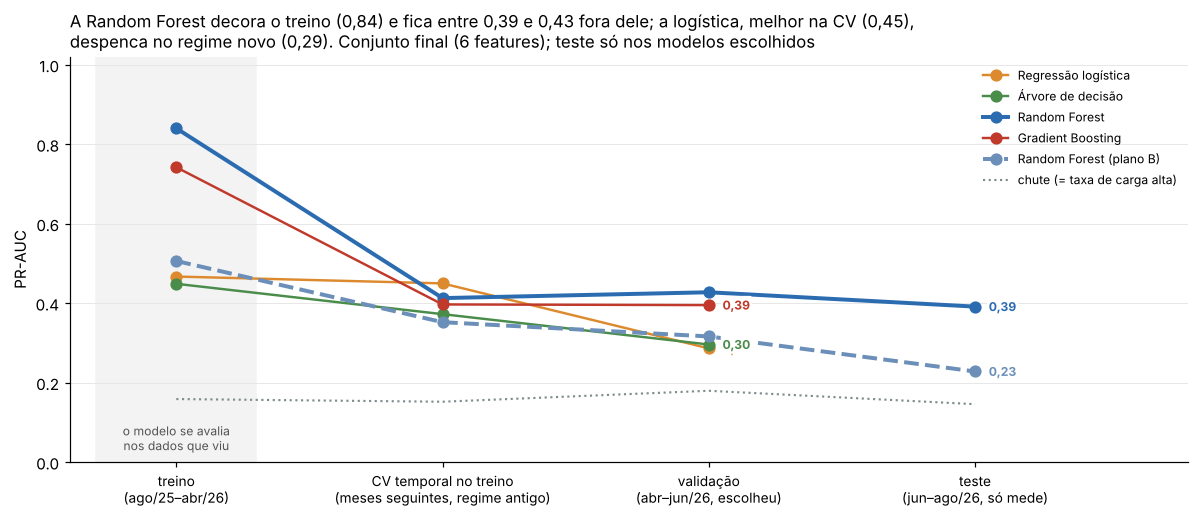

In [15]:
# Gráfico 01: PR-AUC de cada modelo nos quatro lugares
LUGARES = ["treino", "CV temporal", "validação", "teste"]
fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(LUGARES))
for nome, r in tab_gap.iterrows():
    v = r[LUGARES].to_numpy(dtype=float)
    ls = "--" if nome.endswith("(plano B)") else "-"
    lw = 2.6 if nome.startswith("Random Forest") else 1.6
    ax.plot(x, v, ls, marker="o", color=COR[nome], lw=lw, ms=7, label=nome, zorder=3)
    ult = np.where(~np.isnan(v))[0][-1]
    ax.annotate(br(v[ult]), (x[ult], v[ult]), xytext=(9, 0), textcoords="offset points", fontsize=8,
                color=COR[nome], va="center", fontweight="bold", zorder=4,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
ax.plot(x, [CHUTE[l] for l in LUGARES], ":", color=CINZA, lw=1.4, label="chute (= taxa de carga alta)")
ax.legend(fontsize=8, frameon=False, loc="upper right")
ax.axvspan(-0.3, 0.3, color="#f3f3f3", zorder=0)
ax.annotate("o modelo se avalia\nnos dados que viu", (0, 0.03), ha="center", fontsize=8, color="#555")
ax.set_xticks(x, ["treino\n(ago/25–abr/26)", "CV temporal no treino\n(meses seguintes, regime antigo)",
                  "validação\n(abr–jun/26, escolheu)", "teste\n(jun–ago/26, só mede)"], fontsize=9)
ax.set_xlim(-0.4, len(LUGARES) - 0.2)
ax.set_ylim(0, 1.02)
ax.set_ylabel("PR-AUC")
ax.grid(axis="x", visible=False)
rf_g, lr_g = tab_gap.loc["Random Forest"], tab_gap.loc["Regressão logística"]
ax.set_title(f"A Random Forest decora o treino ({br(rf_g['treino'])}) e fica entre {br(rf_g[['CV temporal', 'validação', 'teste']].min())} "
             f"e {br(rf_g[['CV temporal', 'validação', 'teste']].max())} fora dele; a logística, melhor na CV ({br(lr_g['CV temporal'])}),\n"
             f"despenca no regime novo ({br(lr_g['validação'])}). Conjunto final ({len(COLS_A)} features); teste só nos modelos escolhidos",
             loc="left", fontsize=11)
salvar("01_gap_treino_cv_validacao_teste")

### Do simples demais ao complexo demais (slide 11)

A mesma ideia, mudando **só a complexidade**: a profundidade da árvore de decisão e o tamanho
mínimo da folha da Random Forest (folha pequena = modelo mais complexo). Medimos no treino e na
CV temporal, **sem tocar na validação nem no teste**: é só para ver onde estão os modelos
escolhidos na curva, não para escolher de novo.

In [16]:
curva_arv, curva_rf = [], []
for prof in [1, 2, 3, 4, 5, 6, 8, 10, 14]:
    m = montar(DecisionTreeClassifier(max_depth=prof, min_samples_leaf=20, class_weight="balanced", random_state=SEED))
    cv_pr, _ = notas_cv(m, COLS_A)
    p_in = clone(m).fit(treino[COLS_A], y_tr).predict_proba(treino[COLS_A])[:, 1]
    curva_arv.append({"profundidade máxima": prof, "treino": pr(yt_, p_in), "CV": cv_pr.mean(), "CV dp": cv_pr.std()})
for folha in [1, 2, 5, 10, 20, 50, 100, 200]:
    m = floresta(folha=folha)
    cv_pr, _ = notas_cv(m, COLS_A)
    p_in = clone(m).fit(treino[COLS_A], y_tr).predict_proba(treino[COLS_A])[:, 1]
    curva_rf.append({"folha mínima": folha, "treino": pr(yt_, p_in), "CV": cv_pr.mean(), "CV dp": cv_pr.std()})
curva_arv, curva_rf = pd.DataFrame(curva_arv), pd.DataFrame(curva_rf)
print(curva_arv.round(3).to_string(index=False), "\n")
print(curva_rf.round(3).to_string(index=False), "\n")
melhor_folha = curva_rf.loc[curva_rf["CV"].idxmax()]
escolhida = curva_rf.set_index("folha mínima").loc[5]
print(f"Na CV, a folha {int(melhor_folha['folha mínima'])} teria PR-AUC {br(melhor_folha['CV'], 3)} contra "
      f"{br(escolhida['CV'], 3)} da folha 5 escolhida: diferença de {br(melhor_folha['CV'] - escolhida['CV'], 3)}, "
      f"menor que o desvio entre provas ({br(escolhida['CV dp'], 3)}).")

 profundidade máxima  treino    CV  CV dp
                   1   0.223 0.261  0.106
                   2   0.314 0.297  0.102
                   3   0.390 0.375  0.100
                   4   0.449 0.372  0.087
                   5   0.486 0.359  0.076
                   6   0.519 0.345  0.069
                   8   0.563 0.340  0.067
                  10   0.591 0.339  0.067
                  14   0.593 0.339  0.068 

 folha mínima  treino    CV  CV dp
            1   1.000 0.388  0.102
            2   0.990 0.401  0.098
            5   0.840 0.413  0.109
           10   0.700 0.416  0.111
           20   0.605 0.429  0.119
           50   0.542 0.437  0.142
          100   0.513 0.430  0.133
          200   0.484 0.356  0.169 

Na CV, a folha 50 teria PR-AUC 0,437 contra 0,413 da folha 5 escolhida: diferença de 0,024, menor que o desvio entre provas (0,109).


**Leitura.** As duas curvas têm a forma do slide 11: simples demais (árvore de profundidade 1,
floresta com folha de 200) erra no treino **e** fora dele; complexo demais (folha 1) acerta 100%
do treino sem ganhar nada fora dele. Os modelos escolhidos estão na região boa.

Na CV, folhas um pouco maiores que a escolhida (5) dariam nota um pouco melhor. A diferença fica
dentro do desvio entre provas, e a seleção já mostrou que ajustar hiperparâmetros na CV **não**
melhorou a validação (o regime mudou). **Não trocamos nada**: trocar agora seria escolher olhando
de novo, que é o que o slide 29 pede para evitar.

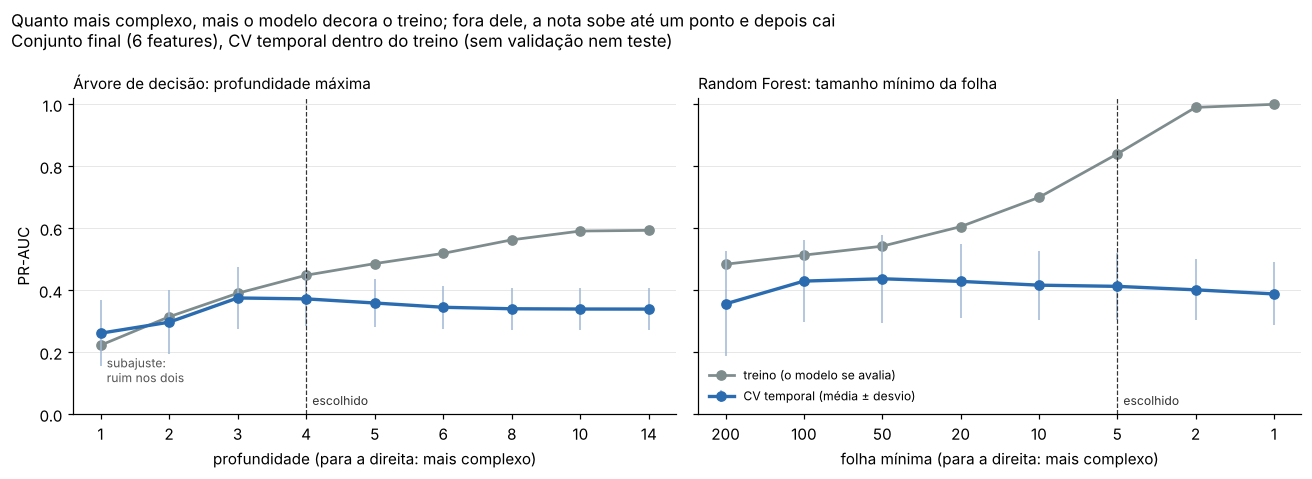

In [17]:
# Gráfico 02: curva de complexidade
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, tab, col, escolhido, titulo, inverter in [
        (axes[0], curva_arv, "profundidade máxima", 4, "Árvore de decisão: profundidade máxima", False),
        (axes[1], curva_rf, "folha mínima", 5, "Random Forest: tamanho mínimo da folha", True)]:
    xs = np.arange(len(tab))
    ax.plot(xs, tab["treino"], "-o", color=CINZA, lw=1.8, ms=6, label="treino (o modelo se avalia)")
    ax.errorbar(xs, tab["CV"], yerr=tab["CV dp"], fmt="-o", color=AZUL, lw=2.2, ms=6, elinewidth=1,
                ecolor="#9fb8d6", capsize=0, label="CV temporal (média ± desvio)")
    i = int(np.where(tab[col] == escolhido)[0][0])
    ax.axvline(xs[i], color="#333", lw=0.8, ls="--")
    ax.annotate("escolhido", (xs[i], 0.03), xytext=(4, 0), textcoords="offset points", fontsize=8, color="#333")
    ax.set_xticks(xs, tab[col].astype(str))
    if inverter:
        ax.invert_xaxis()
        ax.set_xlabel("folha mínima (para a direita: mais complexo)")
    else:
        ax.set_xlabel("profundidade (para a direita: mais complexo)")
    ax.set_title(titulo, loc="left", fontsize=10)
    ax.set_ylim(0, 1.02)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("PR-AUC")
axes[0].annotate("subajuste:\nruim nos dois", (0, curva_arv["CV"].iloc[0]), xytext=(4, -32), textcoords="offset points",
                 fontsize=8, color="#555")
axes[1].legend(fontsize=8, frameon=False, loc="lower left")
fig.suptitle("Quanto mais complexo, mais o modelo decora o treino; fora dele, a nota sobe até um ponto e depois cai\n"
             f"Conjunto final ({len(COLS_A)} features), CV temporal dentro do treino (sem validação nem teste)",
             x=0.01, ha="left", fontsize=11)
salvar("02_complexidade_subajuste_sobreajuste")

## 3. O teste não é uma segunda validação (slides 15 e 29)

A regra de ouro: o teste é usado **uma vez**, no final, e não orienta nenhuma decisão. Abaixo, o
registro de **cada vez** que validação e teste foram olhados no projeto, lido dos scripts e READMEs
de cada etapa. Não é para refazer nada: é para a apresentação dizer, com honestidade, o quanto
cada nota é independente.

In [18]:
uso_particoes = pd.DataFrame([
    ("feature selection §7", "validação", "importância por permutação, medida na validação", "sim: é 1 dos 6 votos"),
    ("feature selection §10", "validação", f"curva desempenho × nº de features; cotovelo em {len(COLS_A)}", "sim: quantas features ficam"),
    ("feature selection §11", "validação", "comparação dos conjuntos (básico, filtro, RFE, L1, consenso...)", "apoio à escolha"),
    ("feature selection §12", "teste", "6 modelos (2 algoritmos × 3 conjuntos); limiar da validação", "não"),
    ("feature selection §13", "validação e teste", "mudança de regime mês a mês (médias e taxa de carga alta)", "não (descritivo)"),
    ("seleção §6 e §7", "validação", "4 algoritmos × 3 conjuntos, de fábrica e ajustados", "sim, junto com a §8"),
    ("seleção §8, 1ª rodada", "teste", "RF ajustada com 22 features: teste 0,369 (nota de 'Transparência')",
     "indireto: depois disso a versão de fábrica entrou como candidata"),
    ("seleção §8", "validação", "escada de modelos com IC 90%", "sim: algoritmo, versão e conjunto"),
    ("seleção §7b", "validação", "desbalanceamento: pesos × sem peso × subamostragem", "não (documenta a estratégia)"),
    ("seleção §9", "validação", "limiares F2, F1 e F0,5", "sim: os três cortes"),
    ("seleção §10", "teste", "conferência única dos planos A e B, com a regra de volume", "não"),
    ("análise §3 a §8", "validação", "baselines, bootstrap, custo por k, calibração, faixas de risco",
     "sim: mapa corte × k; fronteiras das faixas = os limiares"),
    ("análise §8 a §11", "teste", "calibração e faixas, estabilidade, bootstrap contra a regra, custo, modelo para uso", "não"),
    ("análise §8b", "validação e teste", "Platt e isotônica ajustadas na validação, medidas no teste", "não (proposta de exibição)"),
    ("análise §11b a §11d", "validação e teste", "tabela única, segmentos, erros FN/FP, contribuições, regras", "não"),
    ("verificação §1.4 e §1.6", "validação", "timing do histórico e variação por semente", "não"),
    ("verificação §5 e §6", "teste", "distribuição das features; critérios e monitoramento (ilustração)", "não"),
    ("verificação §5b e §5c", "validação e teste", "walk-forward mensal; robustez a erros de pesagem", "não"),
    ("verificação §5c-bis", "validação e teste", "sensibilidade ao corte de peso da camada (0, 100, 1.000 e 2.000 kg)", "não"),
    ("todas as etapas, rodada de out/2026", "validação e teste",
     "pipeline inteiro refeito com o corte de 2.000 kg (resposta da EVCOMX); o teste foi visto de novo",
     "não: o corte veio da EVCOMX, não do teste; as escolhas seguem as regras fixadas antes"),
    ("verificação §6.3 e §6.4", "validação e teste", "validação de domínio e de negócio (cenários)", "não"),
], columns=["etapa", "partição", "o que foi feito", "decidiu algo?"])
print(f"O teste foi olhado em {(uso_particoes['partição'].str.contains('teste')).sum()} momentos, em "
      f"{uso_particoes.loc[uso_particoes['partição'].str.contains('teste'), 'etapa'].str.split(' §').str[0].nunique()} etapas.")
uso_particoes

O teste foi olhado em 12 momentos, em 5 etapas.


,etapa,partição,o que foi feito,decidiu algo?
0,feature selection §7,validação,"importância por permutação, medida na validação",sim: é 1 dos 6 votos
1,feature selection §10,validação,curva desempenho × nº de features; cotovelo em 6,sim: quantas features ficam
2,feature selection §11,validação,"comparação dos conjuntos (básico, filtro, RFE,...",apoio à escolha
3,feature selection §12,teste,6 modelos (2 algoritmos × 3 conjuntos); limiar...,não
4,feature selection §13,validação e teste,mudança de regime mês a mês (médias e taxa de ...,não (descritivo)
5,seleção §6 e §7,validação,"4 algoritmos × 3 conjuntos, de fábrica e ajust...","sim, junto com a §8"
6,"seleção §8, 1ª rodada",teste,"RF ajustada com 22 features: teste 0,369 (nota...",indireto: depois disso a versão de fábrica ent...
7,seleção §8,validação,escada de modelos com IC 90%,"sim: algoritmo, versão e conjunto"
8,seleção §7b,validação,desbalanceamento: pesos × sem peso × subamostr...,não (documenta a estratégia)
9,seleção §9,validação,"limiares F2, F1 e F0,5",sim: os três cortes


**Leitura.**
- **Nenhuma escolha foi feita olhando o teste diretamente.** Features, algoritmo e limiares vieram
  da validação.
- **Mas o teste foi visto antes do fim**, inclusive numa primeira rodada da seleção que mudou a lista
  de candidatos (registrado no README da seleção). Pelo slide 15, ele **não é mais uma avaliação
  totalmente independente**: é uma boa estimativa, não uma prova.
- **A validação fica otimista por construção** (slide 29): ela deu um dos votos da feature
  selection, escolheu quantas features ficam, o algoritmo e os cortes. A nota dela é a do
  "vencedor", e vencedores tendem a ter tido sorte.
  A validação aninhada do slide 29 resolveria, mas com ~90 cargas altas na validação ela não cabe.

**O teste de verdade é o próximo lote.** O jeito limpo de fechar essa questão é pedir à EVCOMX os
dados **depois de 04/08/2026** e rodar o modelo para uso uma única vez, com os critérios da seção 6
já fixados. A tabela abaixo mostra o tamanho do otimismo até aqui.

In [19]:
otimismo = pd.DataFrame({
    "onde foi escolhido (validação)": [tab_gap.loc["Random Forest", "validação"], tab_gap.loc["Random Forest (plano B)", "validação"]],
    "teste": [tab_gap.loc["Random Forest", "teste"], tab_gap.loc["Random Forest (plano B)", "teste"]],
    "chute no teste": [yte_.mean(), yte_.mean()],
}, index=["plano A (com histórico)", "plano B (sem histórico)"])
otimismo["queda"] = otimismo["onde foi escolhido (validação)"] - otimismo["teste"]
otimismo["dp por semente (validação)"] = [pr_seed.std(), np.nan]
otimismo.round(3)

,onde foi escolhido (validação),teste,chute no teste,queda,dp por semente (validação)
plano A (com histórico),0.427,0.391,0.146,0.036,0.004
plano B (sem histórico),0.316,0.228,0.146,0.088,NaN


## 4. Validação cruzada: limites e cuidados (slide 27)

O slide 27 lista os limites da validação cruzada: não substitui a divisão temporal quando o
futuro é o cenário de uso, e grupos relacionados não podem ser separados. Medimos, **no mesmo
treino e com os mesmos modelos**, quatro jeitos de fazer a CV:

| CV | Onde foi usada |
|---|---|
| `cv=5` da aula (`StratifiedKFold`, sem embaralhar) | slide 26 |
| embaralhada, agrupada por corrida (`StratifiedGroupKFold`) | feature selection (L1, Elastic Net, RFE) |
| embaralhada, **sem** agrupar (cestões da mesma corrida separados) | nenhuma: é o pior caso |
| **temporal** (janela crescente, por corrida) | seleção e análise |

Qual delas prevê melhor a nota da validação, que é o "futuro" de verdade? Olhamos três coisas:
o **otimismo** (CV − validação), o **desvio** entre provas (quanta segurança a CV aparenta) e se a
CV **ordena** os algoritmos como a validação.

In [20]:
grupos = treino["cd_corrida"].to_numpy()
ESQUEMAS = {
    "cv=5 da aula": list(StratifiedKFold(n_splits=5).split(treino, y_tr)),
    "embaralhada por corrida (feature selection)": list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
                                                       .split(treino, y_tr, grupos)),
    "embaralhada sem agrupar": list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(treino, y_tr)),
    "temporal (seleção)": CV,
}
linhas = []
for nome_alg in ALGOS:
    for esq, dobras in ESQUEMAS.items():
        prs, _ = notas_cv(ALGOS[nome_alg], COLS_A, dobras=dobras)
        linhas.append({"algoritmo": nome_alg, "CV": esq, "PR-AUC média": prs.mean(), "dp": prs.std()})
tab_esq = pd.DataFrame(linhas)
tab_esq["validação"] = tab_esq["algoritmo"].map(tab_gap["validação"])
tab_esq["CV − validação"] = tab_esq["PR-AUC média"] - tab_esq["validação"]
piv_esq = tab_esq.pivot(index="algoritmo", columns="CV", values="PR-AUC média").loc[list(ALGOS), list(ESQUEMAS)]
piv_esq["validação"] = tab_gap.loc[list(ALGOS), "validação"]
print("PR-AUC média nas 5 provas de cada CV (treino, conjunto final) e a nota real na validação:")
piv_esq.round(3)

PR-AUC média nas 5 provas de cada CV (treino, conjunto final) e a nota real na validação:


CV,cv=5 da aula,embaralhada por corrida (feature selection),embaralhada sem agrupar,temporal (seleção),validação
algoritmo,,,,,
Regressão logística,0.458,0.471,0.469,0.450,0.286
Árvore de decisão,0.384,0.377,0.388,0.372,0.296
Random Forest,0.449,0.469,0.479,0.413,0.427
Gradient Boosting,0.445,0.469,0.471,0.397,0.395


In [21]:
# otimismo, segurança aparente e ordem dos algoritmos, por tipo de CV
ordem_val = piv_esq["validação"].rank(ascending=False)
resumo_esq = pd.DataFrame({
    "otimismo médio (CV − validação)": tab_esq.groupby("CV")["CV − validação"].mean(),
    "erro médio |CV − validação|": tab_esq.groupby("CV")["CV − validação"].apply(lambda s: s.abs().mean()),
    "desvio médio entre provas": tab_esq.groupby("CV")["dp"].mean(),
    "algoritmos na posição certa (de 4)": pd.Series({e: int((piv_esq[e].rank(ascending=False) == ordem_val).sum())
                                                     for e in ESQUEMAS}),
    "1º lugar na CV": pd.Series({e: piv_esq[e].idxmax() for e in ESQUEMAS}),
}).loc[list(ESQUEMAS)]
otim = resumo_esq["otimismo médio (CV − validação)"]
print(f"1º lugar na validação: {piv_esq['validação'].idxmax()}")
resumo_esq.round(3)

1º lugar na validação: Random Forest


,otimismo médio (CV − validação),erro médio |CV − validação|,desvio médio entre provas,algoritmos na posição certa (de 4),1º lugar na CV
cv=5 da aula,0.083,0.083,0.095,0,Regressão logística
embaralhada por corrida (feature selection),0.095,0.095,0.022,0,Regressão logística
embaralhada sem agrupar,0.101,0.101,0.056,2,Random Forest
temporal (seleção),0.057,0.064,0.108,0,Regressão logística


**Leitura.**
- **Embaralhar dá falsa segurança.** As CVs embaralhadas são as mais otimistas **e** as de menor
  desvio: parecem precisas e erram mais. Embaralhar põe meses posteriores no treino de cada
  prova, e o histórico (`taxa_ca_ult5/10`) dos cestões de treino de cada prova contém as cargas
  altas das corridas que estão sendo previstas.
- **A temporal é a menos otimista**, mas com desvio grande. É o preço de ser honesta: cada prova
  é um período diferente, e os períodos são diferentes entre si.
- **Nenhuma CV ordena bem os algoritmos.** Dentro do treino, a logística fica perto das melhores
  em todas as CVs (0,45 a 0,47); na validação ela é a pior (0,29). Nenhuma CV feita **só com o
  regime antigo** consegue ver uma mudança
  que só acontece depois. Por isso a validação temporal (um período posterior, separado) é
  indispensável aqui, e o slide 27 avisa: a CV "não substitui divisão temporal quando o futuro é
  o cenário de uso".
- **Na feature selection**, a CV embaralhada por corrida só escolheu a penalidade do L1/Elastic
  Net e o número de features do RFE (3 dos 6 votos). Ela é otimista para todos os candidatos ao
  mesmo tempo, então o efeito na **ordem** das features deve ser pequeno. Não refazemos: fica
  registrado como limitação.

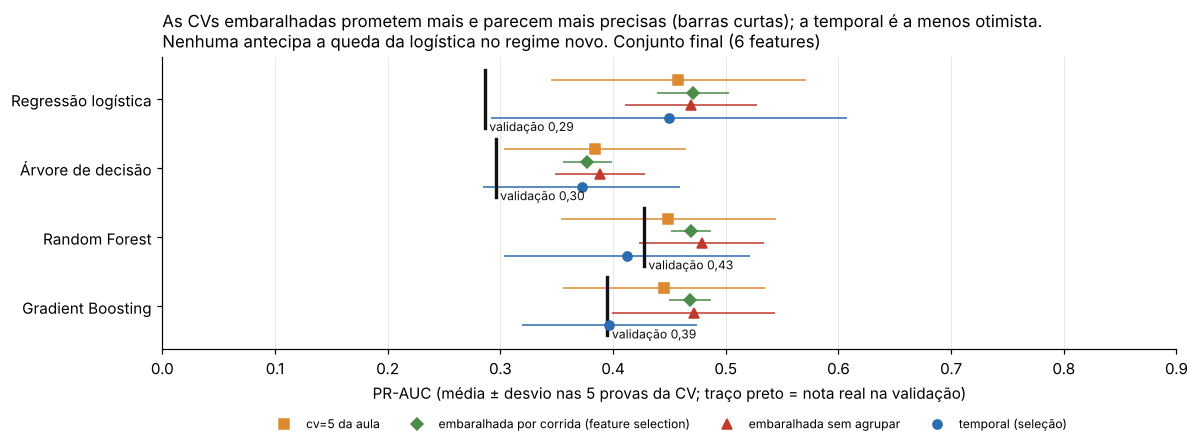

In [22]:
# Gráfico 03: os quatro tipos de CV contra a validação
fig, ax = plt.subplots(figsize=(11, 4.4))
MARC = {"cv=5 da aula": "s", "embaralhada por corrida (feature selection)": "D",
        "embaralhada sem agrupar": "^", "temporal (seleção)": "o"}
CORES_ESQ = {"cv=5 da aula": LARANJA, "embaralhada por corrida (feature selection)": VERDE,
             "embaralhada sem agrupar": VERMELHO, "temporal (seleção)": AZUL}
ypos = np.arange(len(ALGOS))[::-1]
desloc = np.linspace(0.27, -0.27, len(ESQUEMAS))
for y0, alg in zip(ypos, ALGOS):
    for d, esq in zip(desloc, ESQUEMAS):
        r = tab_esq[(tab_esq.algoritmo == alg) & (tab_esq.CV == esq)].iloc[0]
        ax.errorbar(r["PR-AUC média"], y0 + d, xerr=r["dp"], fmt=MARC[esq], color=CORES_ESQ[esq], ms=6,
                    elinewidth=1, capsize=0)
    v = piv_esq.loc[alg, "validação"]
    ax.plot([v, v], [y0 - 0.42, y0 + 0.42], color="#111", lw=2.2)
    ax.annotate(f"validação {br(v)}", (v, y0 - 0.42), xytext=(3, -2), textcoords="offset points", fontsize=8, color="#111")
ax.set_yticks(ypos, list(ALGOS))
ax.set_xlim(0, 0.9)
ax.set_xlabel("PR-AUC (média ± desvio nas 5 provas da CV; traço preto = nota real na validação)")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Line2D([], [], marker=MARC[e], ls="", color=CORES_ESQ[e], ms=6, label=e) for e in ESQUEMAS],
          fontsize=8, frameon=False, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.32))
ax.set_title("As CVs embaralhadas prometem mais e parecem mais precisas (barras curtas); a temporal é a menos otimista.\n"
             f"Nenhuma antecipa a queda da logística no regime novo. Conjunto final ({len(COLS_A)} features)",
             loc="left", fontsize=11)
salvar("03_tipos_de_validacao_cruzada")

## 5. Os dados mudaram? Data drift e concept drift (slides 33 e 34)

O slide 34 separa dois tipos de mudança:
- **Data drift:** a distribuição das features muda;
- **Concept drift:** a **relação** entre as features e a carga alta muda.

A feature selection (seção 13) já mostrou, mês a mês, a média de três features. Aqui medimos as
**features do modelo**, treino contra validação e contra teste, com duas medidas:
- **PSI** (*Population Stability Index*), o padrão de mercado para monitorar modelos: divide o
  treino em 10 faixas e mede quanto a proporção de cestões em cada faixa mudou. Regra usual:
  abaixo de 0,10 estável; de 0,10 a 0,25 mudança moderada; acima de 0,25 mudança grande.
- **KS** (Kolmogorov-Smirnov): a maior distância entre as duas distribuições acumuladas (0 a 1).
  Com centenas de cestões, quase tudo dá p < 0,05; por isso olhamos o tamanho (o PSI e o KS), não
  só o p-valor.

Para o concept drift, comparamos a **correlação de Spearman** de cada feature com a carga alta em
cada partição. Se o sinal muda ou cai para perto de zero, a feature deixou de dizer a mesma coisa.

In [23]:
def psi(ref, novo, faixas=10):
    """PSI com faixas pelos decis da referência. Valores repetidos (features com muitos zeros)
    juntam faixas; um piso de 0,0001 evita log de zero."""
    ref, novo = pd.Series(ref).dropna().to_numpy(), pd.Series(novo).dropna().to_numpy()
    bordas = np.unique(np.quantile(ref, np.linspace(0, 1, faixas + 1))[1:-1])
    a = np.bincount(np.searchsorted(bordas, ref, side="right"), minlength=len(bordas) + 1) / len(ref)
    b = np.bincount(np.searchsorted(bordas, novo, side="right"), minlength=len(bordas) + 1) / len(novo)
    a, b = np.clip(a, 1e-4, None), np.clip(b, 1e-4, None)
    return float(np.sum((b - a) * np.log(b / a)))

def nivel_psi(v):
    return "grande" if v > 0.25 else ("moderada" if v > 0.10 else "estável")

def spearman(d, f):
    return d[f].corr(d["carga_alta"], method="spearman")

linhas = []
for f in COLS_A:
    ks_v, ks_t = ks_2samp(treino[f].dropna(), valid[f].dropna()), ks_2samp(treino[f].dropna(), teste[f].dropna())
    linhas.append({"feature": f,
                   "média treino": treino[f].mean(), "média validação": valid[f].mean(), "média teste": teste[f].mean(),
                   "PSI validação": psi(treino[f], valid[f]), "PSI teste": psi(treino[f], teste[f]),
                   "KS validação": ks_v.statistic, "KS teste": ks_t.statistic, "KS teste p": ks_t.pvalue,
                   "corr. treino": spearman(treino, f), "corr. validação": spearman(valid, f),
                   "corr. teste": spearman(teste, f)})
tab_drift = pd.DataFrame(linhas).set_index("feature")
tab_drift["mudança (PSI máx.)"] = tab_drift[["PSI validação", "PSI teste"]].max(axis=1).map(nivel_psi)

def relacao(r, fraca=0.10):
    """Concept drift em palavras. Correlações abaixo de 0,10 (em módulo) são tratadas como ruído:
    com ~500 cestões por partição, o IC 95% de uma correlação perto de zero é cerca de ±0,09."""
    c0, depois = r["corr. treino"], r[["corr. validação", "corr. teste"]].to_numpy(dtype=float)
    if abs(c0) < fraca:
        return "fraca já no treino"
    if any((np.sign(c) != np.sign(c0)) and abs(c) >= fraca for c in depois):
        return "muda de sinal"
    if np.abs(depois).max() < abs(c0) / 2:
        return "enfraquece"
    if np.abs(depois).min() > abs(c0) * 1.5:
        return "se fortalece"
    return "se mantém"
tab_drift["relação com o alvo"] = tab_drift.apply(relacao, axis=1)
tab_drift = tab_drift.sort_values("PSI teste", ascending=False)
taxa = pd.Series({"treino": yt_.mean(), "validação": yv_.mean(), "teste": yte_.mean()})
print("Taxa de carga alta por partição (mudança no próprio alvo):", taxa.round(3).to_dict())
zeros_hist = pd.Series({n: (d["taxa_ca_ult10"] == 0).mean() for n, d in [("treino", treino), ("validação", valid), ("teste", teste)]})
print("Cestões sem nenhuma carga alta nas 10 corridas anteriores (taxa_ca_ult10 = 0):", zeros_hist.round(3).to_dict())
tab_drift.round(3)

Taxa de carga alta por partição (mudança no próprio alvo): {'treino': 0.159, 'validação': 0.179, 'teste': 0.146}
Cestões sem nenhuma carga alta nas 10 corridas anteriores (taxa_ca_ult10 = 0): {'treino': 0.152, 'validação': 0.154, 'teste': 0.35}


,média treino,média validação,média teste,PSI validação,PSI teste,KS validação,KS teste,KS teste p,corr. treino,corr. validação,corr. teste,mudança (PSI máx.),relação com o alvo
feature,,,,,,,,,,,,,
prop_peso_pesado,0.321,0.205,0.196,0.956,1.525,0.384,0.410,0.000,-0.315,-0.106,-0.072,grande,enfraquece
densidade_media,0.862,0.735,0.738,1.090,1.302,0.424,0.438,0.000,-0.308,0.010,-0.095,grande,enfraquece
peso_por_ciclo_t,18.515,22.174,22.386,0.400,0.694,0.271,0.284,0.000,0.253,0.127,0.082,grande,se mantém
taxa_ca_ult10,0.303,0.314,0.277,0.013,0.579,0.037,0.197,0.000,0.218,0.244,0.382,grande,se mantém
taxa_ca_ult5,0.301,0.316,0.276,0.008,0.243,0.038,0.167,0.000,0.237,0.261,0.379,moderada,se mantém
prop_PACB,0.018,0.005,0.016,0.093,0.001,0.136,0.047,0.289,0.098,0.046,0.180,estável,fraca já no treino


**Leitura.**
- **As features de composição mudaram muito** (data drift): proporção de pesado, densidade e peso
  por ciclo têm PSI bem acima de 0,25. Os cestões do regime novo são **outros cestões**: mais leves,
  menos densos, com ciclos mais "grossos". É o que a feature selection (§13) já tinha visto nas
  médias, agora medido feature a feature.
- **E a relação delas com a carga alta enfraqueceu** (concept drift): no treino, mais pesado e mais
  denso = menos carga alta (correlação ≈ −0,3); no regime novo, essa relação quase some. Isso
  explica por que as regras de composição sozinhas ficam no nível do chute na análise.
- **A relação do histórico com a carga alta se mantém, e até se fortalece no teste** (≈ 0,22 no
  treino, ≈ 0,38 no teste). É o sinal mais estável do projeto. A **distribuição** do histórico
  quase não muda na validação, mas muda no teste: há bem mais cestões sem nenhuma carga alta nas
  10 corridas anteriores (ver a linha impressa acima). O teste tem fases mais longas de forno
  "calmo" e, nelas, o histórico separa ainda melhor.
- **A taxa de carga alta quase não mudou** (0,16 / 0,18 / 0,15): mudou **quem** dá carga alta, não
  **quanto**.

Isso reforça a pergunta 1 do e-mail à EVCOMX (o que mudou em maio): se a mudança for permanente,
o modelo precisa ser re-treinado com o regime novo, e as features de composição precisam provar de
novo que ajudam.

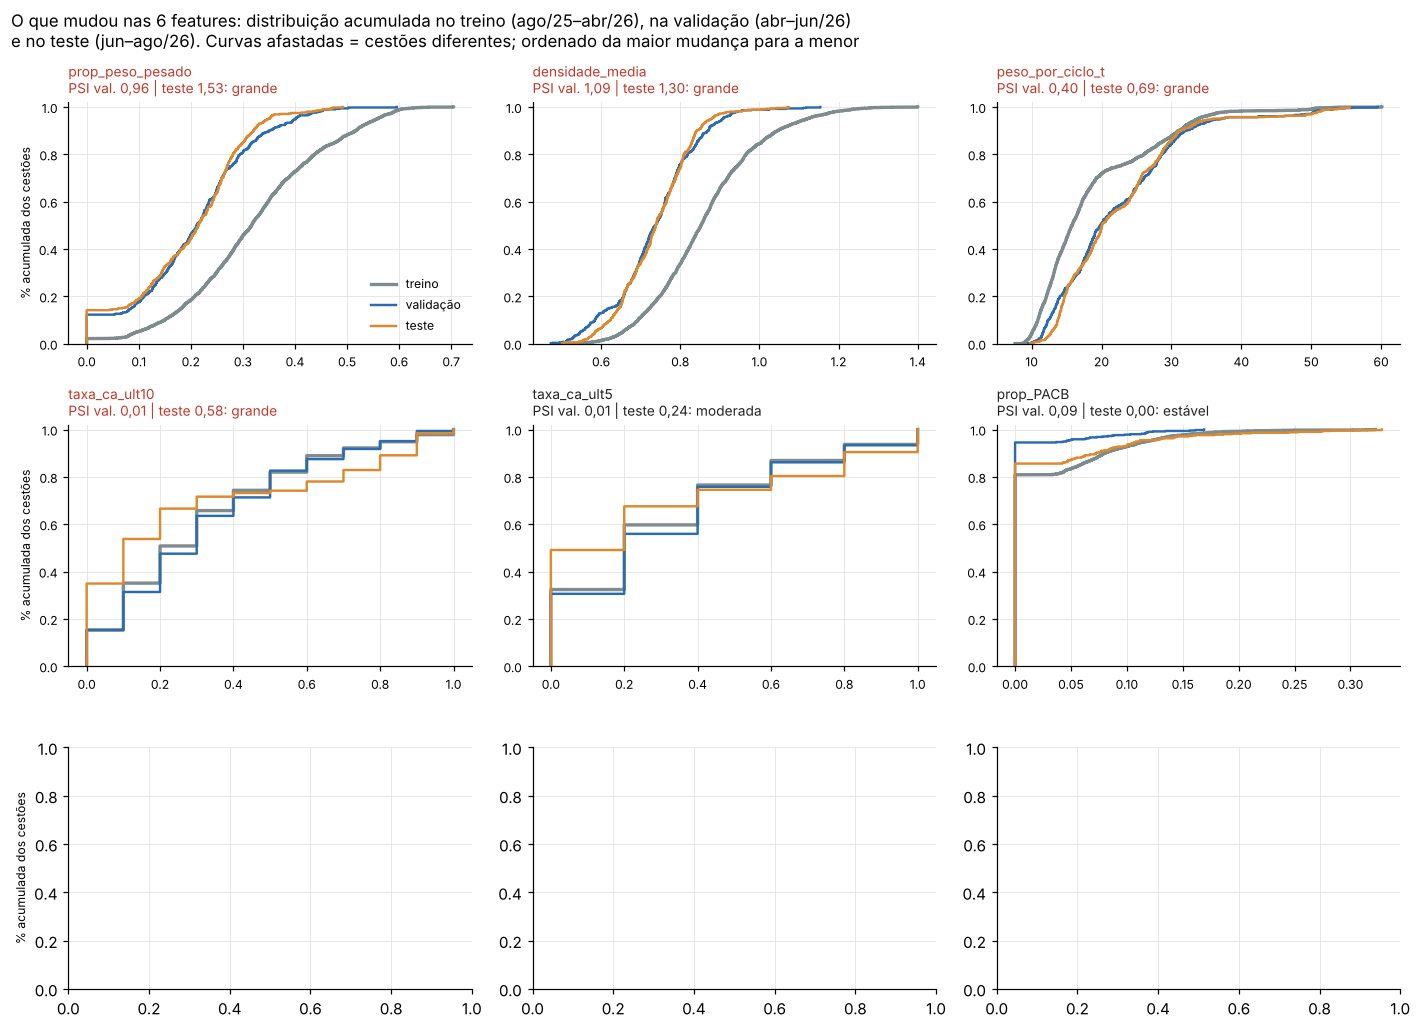

In [24]:
# Gráfico 04: distribuição acumulada de cada feature, por partição
COR_PART = {"treino": CINZA, "validação": AZUL, "teste": LARANJA}
fig, axes = plt.subplots(3, 3, figsize=(13, 9.5))
for ax, f in zip(axes.ravel(), tab_drift.index):
    for nome, d in [("treino", treino), ("validação", valid), ("teste", teste)]:
        v = np.sort(d[f].dropna().to_numpy())
        ax.step(v, np.arange(1, len(v) + 1) / len(v), where="post", color=COR_PART[nome],
                lw=2.2 if nome == "treino" else 1.6, label=nome)
    r = tab_drift.loc[f]
    ax.set_title(f"{f}\nPSI val. {br(r['PSI validação'])} | teste {br(r['PSI teste'])}: {r['mudança (PSI máx.)']}",
                 loc="left", fontsize=9, color=VERMELHO if r["mudança (PSI máx.)"] == "grande" else "#222")
    ax.tick_params(labelsize=8)
    ax.set_ylim(0, 1.02)
for ax in axes[:, 0]:
    ax.set_ylabel("% acumulada dos cestões", fontsize=8)
axes[0, 0].legend(fontsize=8, frameon=False, loc="lower right")
fig.suptitle(f"O que mudou nas {len(COLS_A)} features: distribuição acumulada no treino (ago/25–abr/26), na validação (abr–jun/26)\n"
             "e no teste (jun–ago/26). Curvas afastadas = cestões diferentes; ordenado da maior mudança para a menor",
             x=0.01, ha="left", fontsize=11)
salvar("04_drift_das_features")

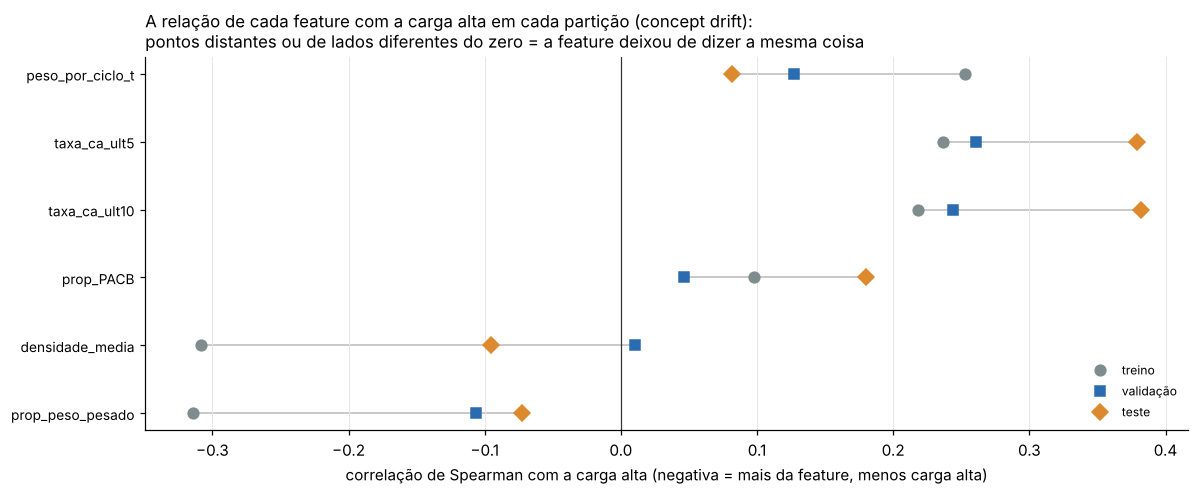

In [25]:
# Gráfico 05: concept drift, correlação de cada feature com a carga alta em cada partição
fig, ax = plt.subplots(figsize=(11, 4.6))
ordem_f = tab_drift.sort_values("corr. treino").index
ypos = np.arange(len(ordem_f))
for nome, col, mk in [("treino", "corr. treino", "o"), ("validação", "corr. validação", "s"), ("teste", "corr. teste", "D")]:
    ax.plot(tab_drift.loc[ordem_f, col], ypos, mk, color=COR_PART[nome], ms=7, label=nome, ls="")
for y0, f in zip(ypos, ordem_f):
    vs = tab_drift.loc[f, ["corr. treino", "corr. validação", "corr. teste"]].to_numpy(dtype=float)
    ax.plot([vs.min(), vs.max()], [y0, y0], color="#bbb", lw=1, zorder=0)
ax.axvline(0, color="#333", lw=0.8)
ax.set_yticks(ypos, ordem_f, fontsize=9)
ax.set_xlabel("correlação de Spearman com a carga alta (negativa = mais da feature, menos carga alta)")
ax.legend(fontsize=8, frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
ax.set_title("A relação de cada feature com a carga alta em cada partição (concept drift):\n"
             "pontos distantes ou de lados diferentes do zero = a feature deixou de dizer a mesma coisa",
             loc="left", fontsize=11)
salvar("05_relacao_feature_alvo_por_particao")

## 5b. Backtesting *walk-forward* mês a mês (Guia de Modelagem §6.2)

O Guia pede: "treinar até o mês t, testar no mês t+1, avançar". É o uso real simulado: a cada mês,
o modelo é re-treinado com **tudo o que já aconteceu** e prevê o mês seguinte. Nada aqui escolhe
nada: algoritmo, features e hiperparâmetros são os do plano A.

Para cada mês reportamos a PR-AUC do modelo, das duas regras (histórico e volume) e o recall com
40 alarmes a cada 100 cestões (o orçamento dos critérios da seção 6). Agosto (poucos dias) foi
somado a julho. A partir de abril/2026 os meses testados são validação e teste: o *walk-forward*
os olha de novo, mas sem escolher nada (registrado na seção 3).

Walk-forward em 7 meses: o modelo fica acima do chute em 7 e acima da regra do histórico em 7.


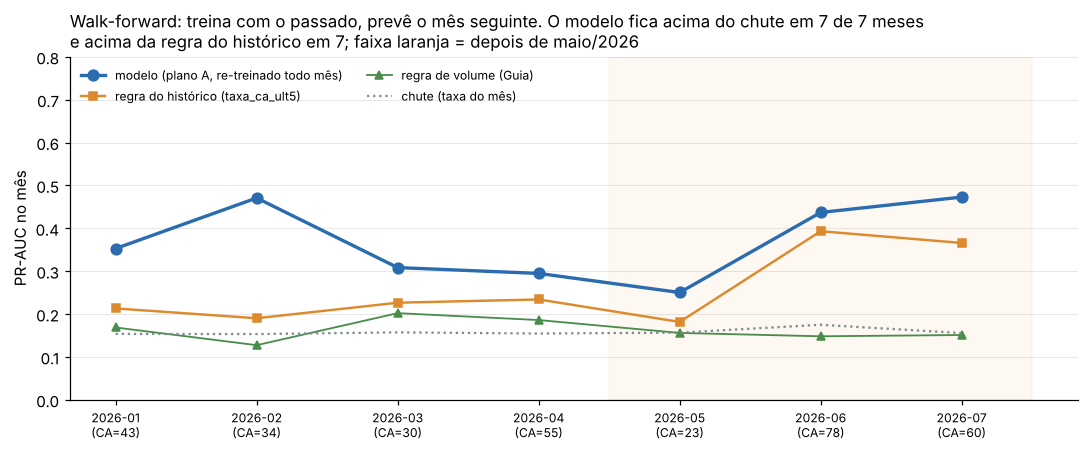

,cestões de treino,cestões no mês,cargas altas,taxa (chute),PR-AUC modelo,PR-AUC regra do histórico,PR-AUC regra de volume,recall modelo (40/100),recall regra histórico (40/100),partição
mês testado,,,,,,,,,,
2026-01,1473,280,43,0.154,0.353,0.213,0.169,0.744,0.580,treino
2026-02,1753,222,34,0.153,0.471,0.190,0.127,0.765,0.556,treino
2026-03,1975,191,30,0.157,0.308,0.226,0.202,0.700,0.626,treino
2026-04,2166,356,55,0.154,0.295,0.234,0.186,0.545,0.492,treino/validacao
2026-05,2522,147,23,0.156,0.250,0.181,0.156,0.565,0.488,validacao
2026-06,2669,446,78,0.175,0.437,0.393,0.148,0.718,0.710,teste/validacao
2026-07,3115,386,60,0.155,0.473,0.366,0.151,0.817,0.825,teste


In [26]:
def recall_orc(y, p, frac=0.40):
    n = int(round(frac * len(p)))
    corte = np.sort(p)[::-1][n - 1]
    acima, empate = p > corte, p == corte
    return (y[acima].sum() + (n - acima.sum()) * y[empate].mean()) / max(y.sum(), 1)

inicio_corr = df.groupby("cd_corrida")["inicio"].transform("min").dt.tz_convert("America/Sao_Paulo")
df["mes_wf"] = inicio_corr.dt.strftime("%Y-%m").replace({"2026-08": "2026-07"})
MESES_WF = [m for m in sorted(df["mes_wf"].unique()) if m >= "2026-01"]
vol_sinal = 1.0   # regra física do Guia: mais volume = mais risco
linhas = []
for mes in MESES_WF:
    tr_, te_ = df[df["mes_wf"] < mes], df[df["mes_wf"] == mes]
    m = clone(floresta()).fit(tr_[COLS_A], tr_["carga_alta"])
    p = m.predict_proba(te_[COLS_A])[:, 1]
    y = te_["carga_alta"].to_numpy()
    p_hist = te_["taxa_ca_ult5"].fillna(tr_["taxa_ca_ult5"].median()).to_numpy()
    linhas.append({"mês testado": mes, "cestões de treino": len(tr_), "cestões no mês": len(te_), "cargas altas": int(y.sum()),
                   "taxa (chute)": y.mean(), "PR-AUC modelo": pr(y, p), "PR-AUC regra do histórico": pr(y, p_hist),
                   "PR-AUC regra de volume": pr(y, vol_sinal * te_["volume_m3_total"].to_numpy()),
                   "recall modelo (40/100)": recall_orc(y, p), "recall regra histórico (40/100)": recall_orc(y, p_hist),
                   "partição": "/".join(sorted(te_["conjunto"].unique()))})
tab_wf = pd.DataFrame(linhas).set_index("mês testado")
vence = (tab_wf["PR-AUC modelo"] > tab_wf["PR-AUC regra do histórico"]).sum()
acima = (tab_wf["PR-AUC modelo"] > tab_wf["taxa (chute)"]).sum()
print(f"Walk-forward em {len(tab_wf)} meses: o modelo fica acima do chute em {acima} e acima da regra do histórico em {vence}.")

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(tab_wf))
ax.plot(x, tab_wf["PR-AUC modelo"], "-o", color=AZUL, lw=2.2, ms=7, label="modelo (plano A, re-treinado todo mês)")
ax.plot(x, tab_wf["PR-AUC regra do histórico"], "-s", color=LARANJA, lw=1.6, ms=5, label="regra do histórico (taxa_ca_ult5)")
ax.plot(x, tab_wf["PR-AUC regra de volume"], "-^", color=VERDE, lw=1.2, ms=5, label="regra de volume (Guia)")
ax.plot(x, tab_wf["taxa (chute)"], ":", color=CINZA, lw=1.5, label="chute (taxa do mês)")
ax.axvspan(MESES_WF.index("2026-05") - 0.5 if "2026-05" in MESES_WF else -0.5, len(x) - 0.5, color=LARANJA, alpha=0.06)
ax.set_xticks(x, [f"{m}\n(CA={c})" for m, c in zip(tab_wf.index, tab_wf["cargas altas"])], fontsize=8)
ax.set_ylabel("PR-AUC no mês")
ax.set_ylim(0, 0.8)
ax.set_title(f"Walk-forward: treina com o passado, prevê o mês seguinte. O modelo fica acima do chute em {acima} de "
             f"{len(tab_wf)} meses\ne acima da regra do histórico em {vence}; faixa laranja = depois de maio/2026",
             loc="left", fontsize=11)
ax.legend(fontsize=8, frameon=False, ncol=2, loc="upper left")
ax.grid(axis="x", visible=False)
salvar("07_walk_forward_mensal")
tab_wf.round(3)

## 5c. Robustez a erros de pesagem (Guia de Modelagem §6.2)

A balança do pátio erra. Quanto as previsões mudam se cada camada tiver um erro de pesagem
realista? Refazemos as features de composição a partir das **camadas** da EDA, com ruído
multiplicativo em cada camada (desvio de 2%, 5% e 10%; o volume da camada acompanha o peso), e
medimos no teste, com o modelo treinado só no treino:
- quanto a chance muda, em média;
- quantos cestões trocam de lado no corte "não deixar passar" (alarme ↔ sem alarme);
- a PR-AUC.

Antes, conferimos que o recálculo **sem ruído** reproduz exatamente as features do dataset.

In [27]:
cam_r = pd.read_csv(RAIZ / "EDA" / "base.csv", usecols=["cd_corrida", "nu_carregamento", "nu_camada", "peso_t", "volume_m3",
                                                         "tp_material", "cd_codigo_material"])
cam_r = cam_r[cam_r.nu_carregamento.isin([1, 2])].sort_values(["cd_corrida", "nu_carregamento", "nu_camada"]).reset_index(drop=True)
cam_r["cd_codigo_material"] = cam_r["cd_codigo_material"].astype(str)
CH = ["cd_corrida", "nu_carregamento"]
g_r = cam_r.groupby(CH)
cam_r["pos_rel"] = g_r.cumcount() / (g_r["nu_camada"].transform("size") - 1).clip(lower=1)
cam_r["bloco"] = (cam_r["tp_material"] != g_r["tp_material"].shift()).groupby([cam_r.cd_corrida, cam_r.nu_carregamento]).cumsum()

def features_composicao(peso, vol):
    c = cam_r.assign(peso_t=peso, volume_m3=vol)
    gg = c.groupby(CH)
    out = pd.DataFrame({"peso": gg["peso_t"].sum(), "vol": gg["volume_m3"].sum()})
    out["densidade_media"] = out["peso"] / out["vol"]
    out["prop_peso_pesado"] = c[c.tp_material == "Pesado"].groupby(CH)["peso_t"].sum().reindex(out.index).fillna(0) / out["peso"]
    bl = c.groupby(CH + ["bloco"]).agg(classe=("tp_material", "first"), v=("volume_m3", "sum")).reset_index()
    n_ciclos = bl[bl.classe == "Pesado"].groupby(CH).size().reindex(out.index).fillna(0)
    out["peso_por_ciclo_t"] = out["peso"] / n_ciclos.clip(lower=1)
    out["max_bloco_leve_m3"] = bl[bl.classe == "Leve"].groupby(CH)["v"].max().reindex(out.index).fillna(0)
    b30 = c[c.pos_rel <= 0.3]
    out["prop_leve_base"] = (b30[b30.tp_material == "Leve"].groupby(CH)["peso_t"].sum().reindex(out.index).fillna(0)
                             / b30.groupby(CH)["peso_t"].sum().reindex(out.index))
    for mat in ["PACB", "PAEP"]:
        out[f"prop_{mat}"] = c[c.cd_codigo_material == mat].groupby(CH)["peso_t"].sum().reindex(out.index).fillna(0) / out["peso"]
    return out.drop(columns=["peso", "vol"]).reset_index()

COMPOS = [c for c in COLS_A if not c.startswith("taxa_ca_")]
f0 = teste[CH].merge(features_composicao(cam_r["peso_t"], cam_r["volume_m3"]), on=CH, how="left")
dif0 = (f0[COMPOS].to_numpy() - teste[COMPOS].to_numpy())
dif0 = np.nanmax(np.abs(dif0))
assert dif0 < 1e-9, f"o recálculo das features não reproduz o dataset (dif. {dif0})"
print(f"Conferência OK: o recálculo sem ruído reproduz as {len(COMPOS)} features de composição do teste (dif. máx. {dif0:.1e})")

modelo_tr = modelos["Random Forest"]
lim_f2 = LIM_A[CENARIOS[0]]
alarme0 = p_te_A >= lim_f2
linhas = []
for sigma in [0.02, 0.05, 0.10]:
    for rep in range(10):
        e = np.random.default_rng(1000 + rep).normal(0, sigma, len(cam_r)).clip(-0.5, 0.5)
        fr = teste[CH].merge(features_composicao(cam_r["peso_t"] * (1 + e), cam_r["volume_m3"] * (1 + e)), on=CH, how="left")
        X_r = teste[COLS_A].copy()
        X_r[COMPOS] = fr[COMPOS].to_numpy()
        p_r = modelo_tr.predict_proba(X_r)[:, 1]
        linhas.append({"erro de pesagem (dp)": f"{sigma:.0%}", "repetição": rep, "|Δ chance| médio": np.abs(p_r - p_te_A).mean(),
                       "% cestões que trocam de lado no corte": 100 * ((p_r >= lim_f2) != alarme0).mean(),
                       "PR-AUC": pr(yte_, p_r)})
tab_ruido = pd.DataFrame(linhas).groupby("erro de pesagem (dp)").agg(["mean", "max"]).drop(columns="repetição")
tab_ruido.columns = [f"{a} ({'média' if b == 'mean' else 'pior'} de 10)" for a, b in tab_ruido.columns]
tab_ruido = tab_ruido.reindex(["2%", "5%", "10%"])
print(f"Sem ruído: PR-AUC no teste {br(pr(yte_, p_te_A), 3)}; {100 * alarme0.mean():.0f} alarmes a cada 100 cestões.")
tab_ruido.round(3)

Conferência OK: o recálculo sem ruído reproduz as 4 features de composição do teste (dif. máx. 7.1e-15)
Sem ruído: PR-AUC no teste 0,391; 38 alarmes a cada 100 cestões.


,|Δ chance| médio (média de 10),|Δ chance| médio (pior de 10),% cestões que trocam de lado no corte (média de 10),% cestões que trocam de lado no corte (pior de 10),PR-AUC (média de 10),PR-AUC (pior de 10)
erro de pesagem (dp),,,,,,
2%,0.012,0.013,1.495,2.524,0.389,0.398
5%,0.023,0.025,3.049,3.689,0.391,0.403
10%,0.037,0.040,5.495,6.602,0.402,0.410


## 5c-bis. Sensibilidade ao corte de peso da camada (resposta da EVCOMX, out/2026)

A EVCOMX disse que camadas de 10 ou 100 kg "também podem ser desconsideradas" e que
"dificilmente temos camadas com menos de 2000kg", e deu 2.000 kg como corte. Por isso a EDA
remove todas as camadas abaixo de 2.000 kg (antes, só as de peso zero). Mas nem tudo abaixo de
2 t parece gancho vazio: entre 100 kg e 2 t a mediana é ~1,6 t. Então medimos o quanto o modelo
depende desse corte.

Para cada corte, refazemos as features de composição do plano A **a partir do arquivo bruto**
(mesma junção, mesmas propriedades estimadas de RECC/RECG e mesma remoção de duplicatas da EDA),
re-treinamos a mesma Random Forest só no treino e medimos na validação e no teste. As features
de histórico não dependem das camadas e ficam iguais. **Nada é escolhido aqui:** o conjunto de
features e os hiperparâmetros são os da rodada com 2.000 kg. Antes, conferimos que o corte de
2.000 kg reproduz exatamente as features do dataset.

In [28]:
CORTES_KG = [("só peso zero (versão anterior)", 1), ("< 100 kg", 100), ("< 1.000 kg", 1000),
             ("< 2.000 kg (EVCOMX, em uso)", 2000)]

bruto_c = pd.read_csv(RAIZ / "original_dataset" / "infos_camadas.csv", na_values=["null"])
mat_c = pd.read_csv(RAIZ / "original_dataset" / "infos_materiais.csv", na_values=["null"])
dic_c = pd.read_csv(RAIZ / "original_dataset" / "dicionario_tipo_material.csv", na_values=["null"])
cam_b = (bruto_c.merge(mat_c, left_on="cd_codigo_material", right_on="Metálico", how="left")
                .merge(dic_c, on="cd_codigo_material", how="left"))
for cod, dens in {"RECC": "2,6", "RECG": "2,8"}.items():   # mesmas estimativas do transforma_dataset.py (A.0b)
    cam_b.loc[cam_b.cd_codigo_material == cod, "Densidade t/m3"] = dens
cam_b = cam_b.drop_duplicates(keep="first")                # bloco A.2
cam_b["Densidade t/m3"] = cam_b["Densidade t/m3"].astype(str).str.replace(",", ".").astype(float)
cam_b["peso_t"] = cam_b["qt_peso_carregamento"] / 1000
cam_b["volume_m3"] = cam_b["peso_t"] / cam_b["Densidade t/m3"]
cam_b["cd_codigo_material"] = cam_b["cd_codigo_material"].astype(str)
cam_b = cam_b[cam_b.nu_carregamento.isin([1, 2])]

def features_de_camadas(c):
    """As features de composição do plano A, a partir de uma tabela de camadas (mesma conta da seção 5c)."""
    c = c.sort_values(CH + ["nu_camada"]).reset_index(drop=True)
    g = c.groupby(CH)
    c["pos_rel"] = g.cumcount() / (g["nu_camada"].transform("size") - 1).clip(lower=1)
    c["bloco"] = (c["tp_material"] != g["tp_material"].shift()).groupby([c.cd_corrida, c.nu_carregamento]).cumsum()
    gg = c.groupby(CH)
    out = pd.DataFrame({"peso": gg["peso_t"].sum(), "vol": gg["volume_m3"].sum(), "n_camadas": gg.size()})
    out["densidade_media"] = out["peso"] / out["vol"]
    out["prop_peso_pesado"] = c[c.tp_material == "Pesado"].groupby(CH)["peso_t"].sum().reindex(out.index).fillna(0) / out["peso"]
    bl = c.groupby(CH + ["bloco"]).agg(classe=("tp_material", "first"), v=("volume_m3", "sum")).reset_index()
    n_ciclos = bl[bl.classe == "Pesado"].groupby(CH).size().reindex(out.index).fillna(0)
    out["peso_por_ciclo_t"] = out["peso"] / n_ciclos.clip(lower=1)
    out["max_bloco_leve_m3"] = bl[bl.classe == "Leve"].groupby(CH)["v"].max().reindex(out.index).fillna(0)
    b30 = c[c.pos_rel <= 0.3]
    out["prop_leve_base"] = (b30[b30.tp_material == "Leve"].groupby(CH)["peso_t"].sum().reindex(out.index).fillna(0)
                             / b30.groupby(CH)["peso_t"].sum().reindex(out.index))
    for mat in sorted({f[5:] for f in COMPOS if f.startswith("prop_") and f[5:].isupper()} | {"PACB", "PAEP"}):
        out[f"prop_{mat}"] = c[c.cd_codigo_material == mat].groupby(CH)["peso_t"].sum().reindex(out.index).fillna(0) / out["peso"]
    return out.drop(columns=["peso", "vol"]).reset_index()

faltando = [f for f in COMPOS if f not in features_de_camadas(cam_b.head(200)).columns]
assert not faltando, f"features_de_camadas não sabe calcular {faltando}: acrescente a conta."

linhas, cestoes_mudam = [], {}
for nome_corte, corte in CORTES_KG:
    cam_k = cam_b[cam_b.qt_peso_carregamento >= corte]
    feats = df[CH].merge(features_de_camadas(cam_k), on=CH, how="left")
    assert feats[COMPOS[0]].notna().all(), f"o corte {nome_corte} apagou cestões inteiros"
    if corte == 2000:
        dif = np.nanmax(np.abs(feats[COMPOS].to_numpy() - df[COMPOS].to_numpy()))
        assert dif < 1e-9, f"o corte de 2.000 kg não reproduz as features do dataset (dif. {dif})"
        print(f"Conferência OK: o corte de 2.000 kg refeito do bruto reproduz as features do dataset (dif. máx. {dif:.1e})")
    d_k = df.copy()
    d_k[COMPOS] = feats[COMPOS].to_numpy()
    tr_k, va_k, te_k = (d_k[d_k.conjunto == c] for c in ["treino", "validacao", "teste"])
    m_k = clone(floresta()).fit(tr_k[COLS_A], tr_k["carga_alta"])
    pv, pt = m_k.predict_proba(va_k[COLS_A])[:, 1], m_k.predict_proba(te_k[COLS_A])[:, 1]
    cestoes_mudam[nome_corte] = feats
    linhas.append({"corte": nome_corte,
                   "camadas removidas (cestões 1 e 2)": int((cam_b.qt_peso_carregamento < corte).sum()),
                   "% do peso removido": 100 * cam_b.loc[cam_b.qt_peso_carregamento < corte, "peso_t"].sum() / cam_b["peso_t"].sum(),
                   "PR-AUC validação": pr(va_k["carga_alta"], pv), "PR-AUC teste": pr(te_k["carga_alta"], pt),
                   "recall 40/100 validação": recall_orc(va_k["carga_alta"].to_numpy(), pv),
                   "recall 40/100 teste": recall_orc(te_k["carga_alta"].to_numpy(), pt)})
tab_corte = pd.DataFrame(linhas).set_index("corte")
ref_corte = cestoes_mudam[CORTES_KG[-1][0]]
for nome_corte, _ in CORTES_KG[:-1]:
    f = cestoes_mudam[nome_corte]
    tab_corte.loc[nome_corte, "% cestões com alguma feature diferente"] = 100 * (
        ~np.isclose(f[COMPOS].to_numpy(), ref_corte[COMPOS].to_numpy(), equal_nan=True)).any(axis=1).mean()
tab_corte.loc[CORTES_KG[-1][0], "% cestões com alguma feature diferente"] = 0.0
amp_val = tab_corte["PR-AUC validação"].max() - tab_corte["PR-AUC validação"].min()
amp_te = tab_corte["PR-AUC teste"].max() - tab_corte["PR-AUC teste"].min()
print(f"Variação da PR-AUC entre os cortes: {br(amp_val, 3)} na validação, {br(amp_te, 3)} no teste "
      f"(referência de ruído: ±0,01 só pela semente; IC 90% da validação ±0,08).")
tab_corte.round(3)

Conferência OK: o corte de 2.000 kg refeito do bruto reproduz as features do dataset (dif. máx. 7.1e-15)
Variação da PR-AUC entre os cortes: 0,026 na validação, 0,011 no teste (referência de ruído: ±0,01 só pela semente; IC 90% da validação ±0,08).


,camadas removidas (cestões 1 e 2),% do peso removido,PR-AUC validação,PR-AUC teste,recall 40/100 validação,recall 40/100 teste,% cestões com alguma feature diferente
corte,,,,,,,
só peso zero (versão anterior),2020,0.000,0.449,0.386,0.717,0.773,57.612
< 100 kg,2346,0.003,0.450,0.380,0.728,0.800,53.042
< 1.000 kg,2732,0.157,0.454,0.382,0.739,0.760,47.386
"< 2.000 kg (EVCOMX, em uso)",5164,2.491,0.427,0.391,0.685,0.773,0.000


## 5d. Calibração (Guia de Modelagem §6.2)

Medida e aplicada na análise de modelos (seções 8 e 8b). Aqui só lemos o resultado para o
checklist de validação: as chances cruas estão infladas; Platt ajustado na validação as corrige
no teste sem mudar a ordem dos cestões.

In [29]:
calib = pd.read_csv(PASTA_AN / "calibracao_aplicada.csv", index_col=0)
print(calib.round(4).to_string())

                                     Brier validação  Brier teste  chance média teste  PR-AUC teste
versão                                                                                             
sem calibrar (como está)                      0.1958       0.1815              0.3872        0.3912
Platt, ajustada na validação                     NaN       0.1090              0.1723        0.3912
isotônica, ajustada na validação                 NaN       0.1101              0.1791        0.3628
Platt, dentro da CV temporal                  0.1381       0.1154              0.2129        0.3586
isotônica, dentro da CV temporal              0.1405       0.1210              0.2250        0.3393
referência: sempre a taxa do treino           0.1476       0.1246              0.1585        0.1456


## 6. Critérios de aceitação e monitoramento (slides 34 e 35)

### 6.1 Critérios de aceitação

O slide 35 pede que os critérios sejam definidos **antes** de olhar o resultado final. No projeto
isso não foi feito: a análise mostrou números, mas nunca escreveu "o que é bom o suficiente".
Agora já é tarde para o teste atual, então os critérios abaixo valem para **o próximo lote de
dados** (o teste de verdade, seção 3). Aplicá-los à validação e ao teste aqui é só uma
**ilustração** de como a conta seria feita.

São uma **proposta do grupo**. Os números de corte (orçamento de alarmes e recall mínimo) dependem
das respostas da EVCOMX (perguntas 3 e "quantos alarmes o pátio aguenta") e estão no topo da
célula, para trocar fácil.

| Critério | Pergunta | Por quê |
|---|---|---|
| C1 | O modelo é melhor que o chute, com folga? | O limite baixo do IC 90% da PR-AUC fica acima da taxa de carga alta do lote |
| C2 | O modelo não perde para a regra do histórico? | No bootstrap pareado, a Random Forest vence em pelo menos 20% dos sorteios (não é "desvantagem provável") |
| C3 | Com o orçamento de alarmes do pátio, pega cargas altas suficientes? | Recall com os `ORCAMENTO` cestões de maior risco a cada 100 ≥ `RECALL_MIN` |
| C4 | As faixas de risco continuam em ordem? | A taxa real de carga alta cresce de "baixo" para "muito alto" |
| C5 (desejável) | O modelo **justifica** sua complexidade? | Vence a regra do histórico com vantagem real (≥ 95% dos sorteios). Se não, a regra simples é uma alternativa honesta (slide 31) |

Os critérios C1 a C4 são o **mínimo para usar**. O C5 decide se vale a pena usar o modelo **em vez
da** regra simples.

In [30]:
ORCAMENTO = 40      # alarmes a cada 100 cestões que o pátio aguenta (A CONFIRMAR COM A EVCOMX)
RECALL_MIN = 0.70   # fração mínima das cargas altas pegas dentro desse orçamento (A CONFIRMAR)
N_BOOT = 1000

rng = np.random.default_rng(SEED)
def amostras_bootstrap(base, n=N_BOOT):
    idx = base.groupby("cd_corrida").indices
    corr = np.array(list(idx))
    return [np.concatenate([idx[c] for c in rng.choice(corr, len(corr))]) for _ in range(n)]

def recall_no_orcamento(y, p, frac):
    """Igual à da análise: recall com os `frac` cestões de maior risco; empates divididos na proporção."""
    y, p = np.asarray(y), np.asarray(p)
    n = int(round(frac * len(p)))
    corte = np.sort(p)[::-1][n - 1]
    acima, empate = p > corte, p == corte
    return (y[acima].sum() + (n - acima.sum()) * y[empate].mean()) / y.sum()

SINAL_REGRA = np.sign(treino[["taxa_ca_ult5", "carga_alta"]].corr(method="spearman").iloc[0, 1])
def regra(base):
    return SINAL_REGRA * base["taxa_ca_ult5"].fillna(treino["taxa_ca_ult5"].median()).to_numpy()

BORDAS_FAIXAS = [0, LIM_A[CENARIOS[0]], LIM_A[CENARIOS[1]], LIM_A[CENARIOS[2]], 1.0001]
FAIXAS = ["baixo", "atenção", "alto", "muito alto"]

def avaliar_lote(nome, base, p):
    y = base["carga_alta"].to_numpy()
    p_r = regra(base)
    boot = amostras_bootstrap(base.reset_index(drop=True))
    v_pr = np.array([pr(y[a], p[a]) for a in boot])
    dif = np.array([pr(y[a], p[a]) - pr(y[a], p_r[a]) for a in boot])
    vence = 100 * (dif > 0).mean()
    rec = recall_no_orcamento(y, p, ORCAMENTO / 100)
    faixa = pd.cut(p, BORDAS_FAIXAS, labels=FAIXAS, right=False)
    taxa_f = pd.Series(y).groupby(faixa, observed=False).mean()
    n_f = pd.Series(y).groupby(faixa, observed=False).size()
    return {"lote": nome, "cestões": len(y), "cargas altas": int(y.sum()), "taxa": y.mean(),
            "PR-AUC": pr(y, p), "PR-AUC IC90 baixo": np.percentile(v_pr, 5),
            "C1 acima do chute": np.percentile(v_pr, 5) > y.mean(),
            "PR-AUC regra": pr(y, p_r), "% sorteios RF vence a regra": vence,
            "C2 não perde para a regra": vence >= 20,
            f"recall c/ {ORCAMENTO} alarmes/100": rec, "C3 recall no orçamento": rec >= RECALL_MIN,
            "taxa real por faixa": " | ".join(f"{v:.0%}" for v in taxa_f),
            "cestões por faixa": " | ".join(str(int(v)) for v in n_f),
            "C4 faixas em ordem": bool(taxa_f.is_monotonic_increasing),
            "C5 supera a regra (desejável)": vence >= 95}

tab_crit = pd.DataFrame([
    avaliar_lote("validação (onde foi escolhido; otimista)", valid, p_va_A),
    avaliar_lote("teste, RF treinada só no treino", teste, p_te_A),
    avaliar_lote("teste, RF para uso (treino + validação)", teste, uso["A"].predict_proba(teste[COLS_A])[:, 1]),
]).set_index("lote")
CRIT_MIN = ["C1 acima do chute", "C2 não perde para a regra", "C3 recall no orçamento", "C4 faixas em ordem"]
tab_crit["mínimo para usar (C1–C4)"] = tab_crit[CRIT_MIN].all(axis=1)
print(f"Critérios com ORCAMENTO = {ORCAMENTO} alarmes/100 e RECALL_MIN = {RECALL_MIN:.0%} (a confirmar com a EVCOMX).")
print("ILUSTRAÇÃO: os critérios foram escritos depois de ver estes números; valem de verdade para o próximo lote.")
print("Faixas: baixo | atenção | alto | muito alto (fronteiras = os três limiares da seleção).\n")
tab_crit.T

Critérios com ORCAMENTO = 40 alarmes/100 e RECALL_MIN = 70% (a confirmar com a EVCOMX).
ILUSTRAÇÃO: os critérios foram escritos depois de ver estes números; valem de verdade para o próximo lote.
Faixas: baixo | atenção | alto | muito alto (fronteiras = os três limiares da seleção).



lote,validação (onde foi escolhido; otimista),"teste, RF treinada só no treino","teste, RF para uso (treino + validação)"
cestões,513,515,515
cargas altas,92,75,75
taxa,0.179337,0.145631,0.145631
PR-AUC,0.427284,0.391209,0.403751
PR-AUC IC90 baixo,0.347614,0.311674,0.333583
C1 acima do chute,True,True,True
PR-AUC regra,0.337178,0.357512,0.357512
% sorteios RF vence a regra,98.5,77.7,87.5
C2 não perde para a regra,True,True,True
recall c/ 40 alarmes/100,0.684783,0.773333,0.813333


**Leitura.** Os critérios não foram ajustados para passar: o que falhou fica registrado.
- **Validação, C3:** com 40 alarmes a cada 100, o modelo pega menos de 70% das cargas altas. O
  corte "não deixar passar" chega lá, mas com ~47 alarmes. Ou seja, o recall mínimo e o
  orçamento de alarmes **competem**, e a EVCOMX precisa decidir qual pesa mais.
- **C4** passa nos três lotes nesta rodada (com o corte de 2.000 kg). Na rodada anterior (corte só
  no peso zero), o modelo para uso trocava a ordem de "alto" e "muito alto". O modelo re-treinado
  continua dando chances mais baixas (análise, seção 11), então **fronteiras fixas em chance não
  se transferem bem entre versões do modelo**: depois de cada re-treino, as fronteiras das faixas
  devem ser recalculadas pelo volume (por exemplo, os 10% de maior risco = "muito alto").
- **C5** só passa na validação, que é onde o modelo foi escolhido. No teste, a Random Forest
  empata com a regra do histórico.

### 6.2 Monitoramento depois da implantação (slide 34)

Depois que o modelo entra em operação, o mundo continua mudando: maio/2026 é a prova. O slide 34
pede: **monitorar, investigar, reavaliar, atualizar se preciso.** A boa notícia é que, neste
problema, o rótulo chega rápido: a carga alta aparece no mesmo dia em que o cestão é despejado.
Dá para medir recall e precisão de verdade, não só a distribuição das features.

Simulamos o painel de monitoramento como se o modelo (plano A, treinado só no treino, corte "não
deixar passar") tivesse entrado em operação no começo da validação, com uma janela a cada 30
dias. Os gatilhos são:

| Gatilho | O que olha | Ação |
|---|---|---|
| G1 dados mudaram | PSI de alguma das features do modelo > 0,25 contra o treino | investigar a origem (processo, coleta, receita) |
| G2 volume de alarmes | alarmes a cada 100 cestões fora de ±15 do esperado | revisar o limiar (fixar pelo volume) |
| G3 recall | recall no corte abaixo de `RECALL_MIN` | reavaliar o corte e o modelo |
| G4 vale o modelo? | PR-AUC da janela ≤ PR-AUC da regra do histórico | o modelo não agregou no período |

O esperado do G2 é o volume de alarmes na validação, onde o corte foi escolhido.

In [31]:
fora = pd.concat([valid.assign(p=p_va_A), teste.assign(p=p_te_A)], ignore_index=True)
t0 = fora["inicio"].min()
fora["janela"] = ((fora["inicio"] - t0).dt.total_seconds() // (30 * 86400)).astype(int)
# a última janela fica com o resto se tiver menos de 15 dias
dias_ult = (fora["inicio"].max() - (t0 + pd.Timedelta(days=30 * fora["janela"].max()))).total_seconds() / 86400
if dias_ult < 15:
    fora.loc[fora.janela == fora.janela.max(), "janela"] -= 1
LIM_F2 = LIM_A[CENARIOS[0]]
ESPERADO = 100 * (p_va_A >= LIM_F2).mean()

linhas = []
for j, g in fora.groupby("janela"):
    y, p = g["carga_alta"].to_numpy(), g["p"].to_numpy()
    psis = {f: psi(treino[f], g[f]) for f in COLS_A}
    f_max = max(psis, key=psis.get)
    prev = p >= LIM_F2
    alarmes = 100 * prev.mean()
    linha = {"janela": f"{g.inicio.min().tz_convert('America/Sao_Paulo'):%d/%m}–{g.inicio.max().tz_convert('America/Sao_Paulo'):%d/%m}",
             "partição": " + ".join({"validacao": "validação", "teste": "teste"}[c]
                                    for c in sorted(g["conjunto"].unique(), reverse=True)),
             "cestões": len(g), "cargas altas": int(y.sum()), "taxa": y.mean(),
             "PSI máx.": psis[f_max], "feature do PSI máx.": f_max,
             "alarmes/100": alarmes, "recall": recall_score(y, prev), "precisão": precision_score(y, prev, zero_division=0),
             "PR-AUC": pr(y, p), "PR-AUC regra": pr(y, regra(g))}
    linha["G1 dados mudaram"] = linha["PSI máx."] > 0.25
    linha["G2 volume de alarmes"] = abs(alarmes - ESPERADO) > 15
    linha["G3 recall"] = linha["recall"] < RECALL_MIN
    linha["G4 não vence a regra"] = linha["PR-AUC"] <= linha["PR-AUC regra"]
    linhas.append(linha)
tab_mon = pd.DataFrame(linhas).set_index("janela")
GATILHOS = ["G1 dados mudaram", "G2 volume de alarmes", "G3 recall", "G4 não vence a regra"]
tab_mon["gatilhos disparados"] = tab_mon[GATILHOS].apply(lambda r: ", ".join(g.split(" ")[0] for g in GATILHOS if r[g]) or "—", axis=1)
print(f"Volume de alarmes esperado (validação, corte '{CURTO[CENARIOS[0]]}'): {ESPERADO:.0f} a cada 100 cestões.")
tab_mon.round(3)

Volume de alarmes esperado (validação, corte 'não deixar passar'): 47 a cada 100 cestões.


,partição,cestões,cargas altas,taxa,PSI máx.,feature do PSI máx.,alarmes/100,recall,precisão,PR-AUC,PR-AUC regra,G1 dados mudaram,G2 volume de alarmes,G3 recall,G4 não vence a regra,gatilhos disparados
janela,,,,,,,,,,,,,,,,
25/04–25/05,validação,158,21,0.133,0.811,prop_peso_pesado,37.975,0.571,0.200,0.243,0.151,True,False,True,False,"G1, G3"
26/05–24/06,validação + teste,360,74,0.206,1.957,densidade_media,51.944,0.824,0.326,0.465,0.402,True,False,False,False,G1
24/06–04/08,validação + teste,510,72,0.141,1.501,prop_peso_pesado,37.647,0.750,0.281,0.391,0.346,True,False,False,False,G1


**Leitura.**
- **O G1 dispara desde a primeira janela.** Se o modelo treinado até abril estivesse em operação,
  o monitoramento teria avisado **já em maio** que os cestões mudaram, antes de qualquer queda de
  desempenho aparecer. É exatamente o papel do monitoramento (slide 34).
- **G2, G3 e G4 não dispararam:** o volume de alarmes, o recall e a vantagem sobre a regra se
  seguraram nas três janelas. O modelo aguentou a mudança porque o histórico (estável) carrega boa
  parte da previsão.
- **Um G1 sempre ligado perde a utilidade.** Depois do re-treino com o regime novo, a referência do
  PSI precisa passar a ser o novo treino. Senão, o alarme toca para sempre.

**Plano de monitoramento proposto** (o rótulo chega no mesmo dia, então dá para medir tudo):

| O quê | Frequência | Gatilho | Ação |
|---|---|---|---|
| PSI das features do modelo contra o treino do modelo em uso | semanal | > 0,25 em alguma feature | investigar com a EVCOMX: mudou o processo, a receita ou a coleta? |
| Alarmes a cada 100 cestões | semanal | fora de ±15 do esperado | revisar o limiar pelo volume de alarmes |
| Recall e precisão no corte | mensal (~380 cestões, ~55 cargas altas) | recall < mínimo combinado | reavaliar o corte e o modelo |
| PR-AUC do modelo × regra do histórico | mensal | modelo ≤ regra | o modelo não agregou no mês; se repetir, voltar à regra |
| Taxa real por faixa de risco | mensal | faixas fora de ordem | recalcular as fronteiras das faixas |
| Re-treino | quando G1 ou G3 dispararem por 2 janelas seguidas, ou a cada 3 meses | — | re-treinar com os dados recentes, recalcular os limiares pelo volume e rodar esta verificação de novo |

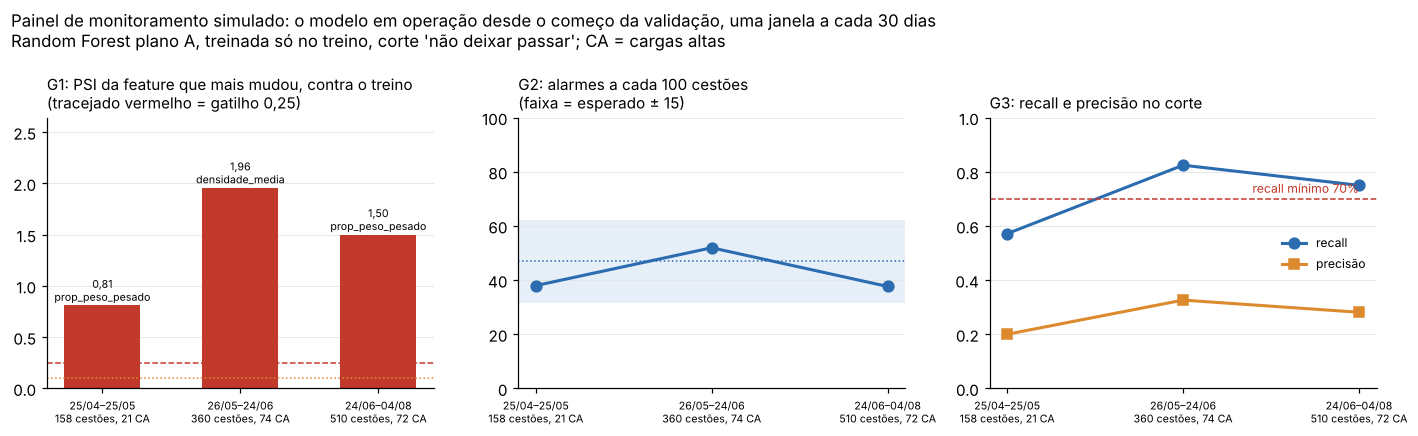

In [32]:
# Gráfico 06: o painel de monitoramento simulado
fig, axes = plt.subplots(1, 3, figsize=(13, 4.0))
x = np.arange(len(tab_mon))
rot_x = [f"{j}\n{n} cestões, {c} CA" for j, n, c in zip(tab_mon.index, tab_mon["cestões"], tab_mon["cargas altas"])]
ax = axes[0]
ax.bar(x, tab_mon["PSI máx."], color=[VERMELHO if v > 0.25 else (LARANJA if v > 0.10 else VERDE) for v in tab_mon["PSI máx."]],
       width=0.55)
for xi, v, f in zip(x, tab_mon["PSI máx."], tab_mon["feature do PSI máx."]):
    ax.annotate(f"{br(v)}\n{f}", (xi, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=7)
ax.axhline(0.25, color=VERMELHO, ls="--", lw=1); ax.axhline(0.10, color=LARANJA, ls=":", lw=1)
ax.set_title("G1: PSI da feature que mais mudou, contra o treino\n(tracejado vermelho = gatilho 0,25)", loc="left", fontsize=10)
ax.set_ylim(0, max(0.4, tab_mon["PSI máx."].max() * 1.35))
ax = axes[1]
ax.plot(x, tab_mon["alarmes/100"], "-o", color=AZUL, lw=2, ms=7)
ax.axhspan(ESPERADO - 15, ESPERADO + 15, color="#e6eef7", zorder=0)
ax.axhline(ESPERADO, color=AZUL, ls=":", lw=1)
ax.set_title("G2: alarmes a cada 100 cestões\n(faixa = esperado ± 15)", loc="left", fontsize=10)
ax.set_ylim(0, 100)
ax = axes[2]
ax.plot(x, tab_mon["recall"], "-o", color=AZUL, lw=2, ms=7, label="recall")
ax.plot(x, tab_mon["precisão"], "-s", color=LARANJA, lw=2, ms=6, label="precisão")
ax.axhline(RECALL_MIN, color=VERMELHO, ls="--", lw=1)
ax.annotate(f"recall mínimo {RECALL_MIN:.0%}", (x[-1], RECALL_MIN), xytext=(0, 4), textcoords="offset points",
            ha="right", fontsize=8, color=VERMELHO)
ax.set_title("G3: recall e precisão no corte", loc="left", fontsize=10)
ax.set_ylim(0, 1)
ax.legend(fontsize=8, frameon=False, loc="center right")
for ax in axes:
    ax.set_xticks(x, rot_x, fontsize=7)
    ax.grid(axis="x", visible=False)
fig.suptitle(f"Painel de monitoramento simulado: o modelo em operação desde o começo da validação, uma janela a cada 30 dias\n"
             f"Random Forest plano A, treinada só no treino, corte '{CURTO[CENARIOS[0]]}'; CA = cargas altas",
             x=0.01, ha="left", fontsize=11)
salvar("06_monitoramento_simulado")

### 6.3 Validação de domínio: o modelo faz sentido físico? (Guia de Modelagem §6.3)

As cinco perguntas do Guia, cada uma com a evidência que temos. A "evidência esperada" é a do
Guia; a coluna "o que encontramos" diz se ela apareceu. **Se o modelo contradiz a física, é
preciso investigar antes de comemorar** (vazamento, confundimento ou erro de dado).

Fontes: dependência parcial (análise §11d, `dependencia_parcial_sentido.csv`), taxas reais por
grupo (treino e validação + teste), as flags de violação da ordem (`features_guia_modelagem.csv`,
da feature selection §11b) e os casos para o especialista (análise §11c).

In [33]:
pdp = pd.read_csv(PASTA_AN / "dependencia_parcial_sentido.csv", index_col=0)
flags = pd.read_csv(PASTA_FS / "features_guia_modelagem.csv")
# uma flag pode já estar entre as candidatas (ex.: violacao_regra, quando não é quase constante): não duplicar
flags = flags[["cd_corrida", "nu_carregamento"] + [c for c in flags.columns if c not in df.columns]]
dd = df.merge(flags, on=["cd_corrida", "nu_carregamento"], how="left")
dd["p_A"] = np.nan
dd.loc[dd.conjunto == "validacao", "p_A"] = p_va_A
dd.loc[dd.conjunto == "teste", "p_A"] = p_te_A
assert (dd.loc[dd.conjunto == "validacao", "cd_corrida"].to_numpy() == valid["cd_corrida"].to_numpy()).all()
tr_, vt_ = dd[dd.conjunto == "treino"], dd[dd.conjunto != "treino"]

def taxa_por(d, col, q=None):
    if q is not None:
        return d.groupby(pd.qcut(d[col], q, duplicates="drop"), observed=True)["carga_alta"].mean().round(2).tolist()
    return d.groupby(col)["carga_alta"].mean().round(2).to_dict()

from scipy.stats import spearmanr
rho_vol = spearmanr(vt_["volume_m3_total"], vt_["p_A"]).statistic
viol = {c: (taxa_por(tr_, c), taxa_por(vt_, c), vt_.groupby(c)["p_A"].mean().round(2).to_dict())
        for c in ["violacao_fundo_topo", "violacao_regra"]}
ext = vt_[(vt_["densidade_media"] <= vt_["densidade_media"].quantile(0.05)) |
          (vt_["peso_por_ciclo_t"] >= vt_["peso_por_ciclo_t"].quantile(0.95))]
lim_f2 = LIM_A[CENARIOS[0]]
sobe = lambda c: pdp.loc[c, "variação"] > 0
# features do modelo que medem "leve/volumoso" (a lista depende do conjunto final da feature selection)
FEAT_LEVE = [c for c in ["max_bloco_leve_m3", "prop_leve_base", "prop_leve", "prop_PACB", "prop_PAEP"] if c in pdp.index]

tab_dominio = pd.DataFrame([
    ("O risco aumenta quando o volume aumenta?",
     "curva crescente na dependência parcial do volume",
     f"NÃO nestes dados. O volume não entrou no modelo (feature selection: r = {tr_[['volume_m3_total', 'carga_alta']].corr().iloc[0, 1]:+.2f} "
     f"no treino). Taxa real por tercil de volume no treino: {taxa_por(tr_, 'volume_m3_total', 3)}; Spearman entre volume e risco "
     f"previsto (validação + teste): {rho_vol:+.2f}. O que pesa é a densidade: a dependência parcial de densidade_media "
     f"{'cai' if not sobe('densidade_media') else 'sobe'} ({pdp.loc['densidade_media', 'variação']:+.2f}) e a de prop_peso_pesado "
     f"{'cai' if not sobe('prop_peso_pesado') else 'sobe'} ({pdp.loc['prop_peso_pesado', 'variação']:+.2f}).",
     "o volume não diz nada; a física aparece pela densidade e pelo pesado"
     if not sobe("densidade_media") and not sobe("prop_peso_pesado") else "investigar"),
    ("Materiais leves em excesso elevam o risco?",
     "contribuição positiva das features de leve",
     "Dependência parcial: " + ", ".join(f"{c} {pdp.loc[c, 'variação']:+.2f}" for c in FEAT_LEVE)
     + " (variação da chance do menor ao maior valor).",
     "coerente" if all(sobe(c) for c in FEAT_LEVE) else "parcial: ver concept drift (seção 5)"),
    ("A violação da ordem das camadas aumenta o risco?",
     "efeito consistente com a regra leve–pesado–leve",
     f"Taxa real com/sem violação (fundo ou topo não leve): treino {viol['violacao_fundo_topo'][0]}, validação + teste "
     f"{viol['violacao_fundo_topo'][1]}; pesado no fundo/topo: treino {viol['violacao_regra'][0]}. Nenhuma das flags "
     "teve votos para entrar no modelo (feature selection §3 e §11b).",
     ("inverte entre regimes: menos risco no treino, mais risco depois de maio; rever com dados novos"
      if viol["violacao_fundo_topo"][0].get(1, 0) < viol["violacao_fundo_topo"][0].get(0, 0)
      and viol["violacao_fundo_topo"][1].get(1, 0) > viol["violacao_fundo_topo"][1].get(0, 0)
      else "não confirmado nos dados" if viol["violacao_fundo_topo"][0].get(1, 0) <= viol["violacao_fundo_topo"][0].get(0, 0) + 0.02
      else "coerente, mas fora do modelo")),
    ("Casos extremos se comportam bem?",
     "cestões 'impossíveis' recebem risco alto",
     f"{len(ext)} cestões extremos (5% menos densos ou 5% com mais toneladas por ciclo, validação + teste): risco médio "
     f"{br(ext['p_A'].mean())} contra {br(vt_['p_A'].mean())} no geral; {100 * (ext['p_A'] >= lim_f2).mean():.0f}% dão alarme "
     f"no corte F2 (geral: {100 * (vt_['p_A'] >= lim_f2).mean():.0f}%); taxa real neles {100 * ext['carga_alta'].mean():.0f}% "
     f"(geral {100 * vt_['carga_alta'].mean():.0f}%).",
     ("o modelo segue a física (risco alto), mas no regime novo esses cestões não têm mais carga alta que a média"
      if ext["p_A"].mean() > vt_["p_A"].mean() and ext["carga_alta"].mean() <= vt_["carga_alta"].mean() + 0.02
      else "coerente" if ext["p_A"].mean() > vt_["p_A"].mean() else "investigar")),
    ("O modelo concorda com o especialista?",
     "revisão qualitativa com operadores/engenheiros do pátio",
     "Pendente: os 10 alarmes falsos mais 'certos' e as 10 cargas altas com menor risco estão em "
     "analise_modelos/casos_para_especialista.csv, para revisar com a EVCOMX.",
     "pendente (EVCOMX)"),
], columns=["pergunta do Guia", "evidência esperada", "o que encontramos", "veredito"]).set_index("pergunta do Guia")
for q, r in tab_dominio.iterrows():
    print(f"- {q}\n  [{r['veredito']}] {r['o que encontramos']}\n")

- O risco aumenta quando o volume aumenta?
  [o volume não diz nada; a física aparece pela densidade e pelo pesado] NÃO nestes dados. O volume não entrou no modelo (feature selection: r = -0.04 no treino). Taxa real por tercil de volume no treino: [0.2, 0.12, 0.16]; Spearman entre volume e risco previsto (validação + teste): -0.10. O que pesa é a densidade: a dependência parcial de densidade_media cai (-0.14) e a de prop_peso_pesado cai (-0.21).

- Materiais leves em excesso elevam o risco?
  [coerente] Dependência parcial: prop_PACB +0.01 (variação da chance do menor ao maior valor).

- A violação da ordem das camadas aumenta o risco?
  [inverte entre regimes: menos risco no treino, mais risco depois de maio; rever com dados novos] Taxa real com/sem violação (fundo ou topo não leve): treino {0: 0.17, 1: 0.12}, validação + teste {0: 0.13, 1: 0.21}; pesado no fundo/topo: treino {0: 0.16, 1: 0.05}. Nenhuma das flags teve votos para entrar no modelo (feature selection §3 e §11b).

- Casos

### 6.4 Validação de negócio: vale a pena? (Guia de Modelagem §6.4)

A conta do Guia:

```
eventos_evitados = VP × taxa_de_sucesso_da_intervenção
minutos_poupados = eventos_evitados × duração_média_da_parada
custo_alarmes    = FP × custo_de_um_alarme_falso
ganho_líquido    = minutos_poupados − custo_alarmes
```

**O que temos e o que não temos.** A duração média da parada sai dos dados (treino). A taxa de
sucesso da intervenção, o custo de um alarme falso e o valor do minuto de forno parado **só a
EVCOMX sabe** (pergunta 3 do e-mail). Por isso:
- o custo do alarme falso entra em **minutos de forno equivalentes** (o mesmo `k` da análise:
  `k = duração média ÷ custo do alarme`);
- apresentamos **três cenários** (conservador, base, otimista), nunca um número único, e uma grade
  de sensibilidade;
- `CUSTO_MINUTO_RS` fica vazio: quando a EVCOMX informar o valor do minuto, basta preenchê-lo e as
  tabelas saem em reais.

Estratégias comparadas no **teste** (jun–ago/2026), sempre com limiares escolhidos antes dele:
o modelo (plano A, treinado só no treino, cortes da validação), a **regra de volume** do Guia e a
**regra do histórico** (limiares de melhor F2 no treino). Para comparar modelo e regra **com o
mesmo número de alarmes**, há também a linha "modelo, mesmo nº de alarmes da regra" (os N cestões
de maior risco do teste, N = alarmes da regra; é a forma de operar recomendada na análise, corte
pelo volume de alarmes). Os valores mensal e anual são a extrapolação do ritmo do teste.

In [34]:
CUSTO_MINUTO_RS = None   # R$ por minuto de forno parado: preencher com o valor da EVCOMX
CENARIOS_NEG = {          # (taxa de sucesso da intervenção, custo de 1 alarme falso em minutos de forno)
    "conservador": (0.30, 2.0),
    "base": (0.50, 1.0),
    "otimista": (0.80, 0.5),
}
DUR_MIN = treino.loc[treino.carga_alta == 1, "seg_parada"].mean() / 60
dias_teste = (teste["inicio"].max() - teste["inicio"].min()).total_seconds() / 86400

def limiar_f2_regra(score, y, alarmes_max=0.5):
    cand_l = np.unique(np.quantile(score, np.linspace(0.5, 0.99, 50)))
    f = []
    for l in cand_l:
        a = score > l
        vp = (a & (y == 1)).sum()
        prec, rec = vp / max(a.sum(), 1), vp / y.sum()
        f.append(5 * prec * rec / max(4 * prec + rec, 1e-12) if a.mean() <= alarmes_max else -1)
    return float(cand_l[int(np.argmax(f))])

s_vol_tr, s_vol_te = treino["volume_m3_total"].to_numpy(), teste["volume_m3_total"].to_numpy()
s_hist_tr = treino["taxa_ca_ult5"].fillna(treino["taxa_ca_ult5"].median()).to_numpy()
s_hist_te = teste["taxa_ca_ult5"].fillna(treino["taxa_ca_ult5"].median()).to_numpy()
L_VOL, L_HIST = limiar_f2_regra(s_vol_tr, yt_), limiar_f2_regra(s_hist_tr, yt_)
alarme_hist = s_hist_te > L_HIST
top_n = np.zeros(len(p_te_A), dtype=bool)
top_n[np.argsort(-p_te_A, kind="stable")[:alarme_hist.sum()]] = True     # mesmo nº de alarmes da regra
ESTRATEGIAS = {
    f"modelo, corte '{CURTO[CENARIOS[0]]}'": p_te_A >= LIM_A[CENARIOS[0]],
    f"modelo, corte '{CURTO[CENARIOS[1]]}'": p_te_A >= LIM_A[CENARIOS[1]],
    "modelo, mesmo nº de alarmes da regra do histórico": top_n,
    f"regra de volume (> {L_VOL:.0f} m³)": s_vol_te > L_VOL,
    f"regra do histórico (taxa_ca_ult5 > {L_HIST:.1f})": alarme_hist,
}
linhas = []
for nome, alarme in ESTRATEGIAS.items():
    vp, fp = int((alarme & (yte_ == 1)).sum()), int((alarme & (yte_ == 0)).sum())
    for cen, (sucesso, custo_fp) in CENARIOS_NEG.items():
        ganho = vp * sucesso * DUR_MIN - fp * custo_fp
        lin = {"estratégia": nome, "cenário": cen, "VP": vp, "FP": fp, "alarmes/100": 100 * alarme.mean(),
               "eventos evitados /30 dias": vp * sucesso / dias_teste * 30,
               "min. poupados /30 dias": vp * sucesso * DUR_MIN / dias_teste * 30,
               "custo alarmes (min) /30 dias": fp * custo_fp / dias_teste * 30,
               "ganho líquido (min) /30 dias": ganho / dias_teste * 30,
               "ganho líquido (min) /ano": ganho / dias_teste * 365}
        if CUSTO_MINUTO_RS:
            lin["ganho líquido (R$) /30 dias"] = lin["ganho líquido (min) /30 dias"] * CUSTO_MINUTO_RS
            lin["ganho líquido (R$) /ano"] = lin["ganho líquido (min) /ano"] * CUSTO_MINUTO_RS
        linhas.append(lin)
tab_negocio = pd.DataFrame(linhas).set_index(["estratégia", "cenário"])
print(f"Duração média de uma parada (treino): {DUR_MIN:.1f} min. Teste: {len(teste)} cestões em {dias_teste:.0f} dias; "
      f"{int(yte_.sum())} cargas altas = {yte_.sum() * DUR_MIN / dias_teste * 30:.0f} min de parada a cada 30 dias, se nada for feito.")
print("Valor do minuto em R$: " + (f"{CUSTO_MINUTO_RS}" if CUSTO_MINUTO_RS else "não informado (os ganhos estão em minutos de forno)"))
tab_negocio["ganho líquido (min) /30 dias"].unstack().loc[list(ESTRATEGIAS), list(CENARIOS_NEG)].round(1)

Duração média de uma parada (treino): 4.0 min. Teste: 515 cestões em 41 dias; 75 cargas altas = 223 min de parada a cada 30 dias, se nada for feito.
Valor do minuto em R$: não informado (os ganhos estão em minutos de forno)


cenário,conservador,base,otimista
estratégia,,,
"modelo, corte 'não deixar passar'",-156.8,-19.2,83.4
"modelo, corte 'equilíbrio'",-95.0,1.3,77.3
"modelo, mesmo nº de alarmes da regra do histórico",-122.9,-7.5,81.1
regra de volume (> 56 m³),-310.2,-113.6,8.5
regra do histórico (taxa_ca_ult5 > 0.2),-111.1,3.6,94.8


Com o mesmo nº de alarmes da regra (167), o modelo acerta 52 cargas altas e a regra 57.
Modelo × regra do histórico na grade inteira: sempre a favor da regra (de -26 a -1 min a cada 30 dias).


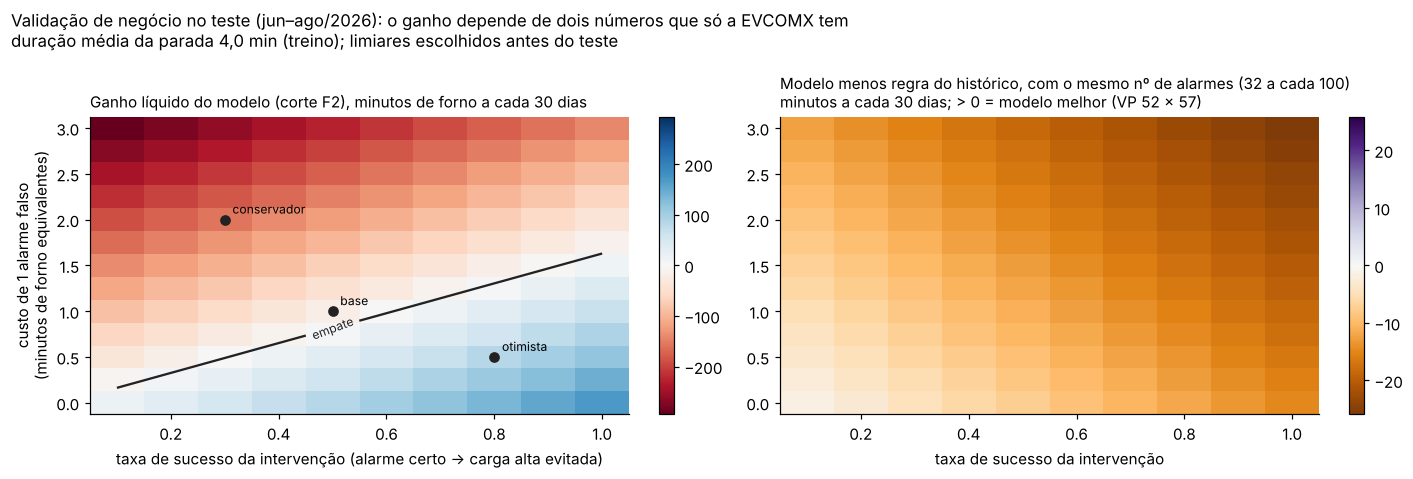

In [35]:
# Sensibilidade: ganho líquido mensal do modelo (corte F2) para cada taxa de sucesso e custo do alarme
alarme = ESTRATEGIAS[f"modelo, corte '{CURTO[CENARIOS[0]]}'"]
vp, fp = (alarme & (yte_ == 1)).sum(), (alarme & (yte_ == 0)).sum()
alarme_h = ESTRATEGIAS[f"regra do histórico (taxa_ca_ult5 > {L_HIST:.1f})"]
vp_h, fp_h = (alarme_h & (yte_ == 1)).sum(), (alarme_h & (yte_ == 0)).sum()
vp_n, fp_n = (top_n & (yte_ == 1)).sum(), (top_n & (yte_ == 0)).sum()
SUCESSOS = np.linspace(0.1, 1.0, 10)
CUSTOS = np.linspace(0, 3, 13)
grade = np.array([[(vp * s * DUR_MIN - fp * c) / dias_teste * 30 for s in SUCESSOS] for c in CUSTOS])
grade_h = np.array([[(vp_h * s * DUR_MIN - fp_h * c) / dias_teste * 30 for s in SUCESSOS] for c in CUSTOS])
grade_n = np.array([[(vp_n * s * DUR_MIN - fp_n * c) / dias_teste * 30 for s in SUCESSOS] for c in CUSTOS])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
lim_c = np.abs(grade).max()
im = axes[0].imshow(grade, origin="lower", aspect="auto", cmap="RdBu", vmin=-lim_c, vmax=lim_c,
                    extent=[SUCESSOS[0] - 0.05, SUCESSOS[-1] + 0.05, CUSTOS[0] - 0.125, CUSTOS[-1] + 0.125])
cs = axes[0].contour(SUCESSOS, CUSTOS, grade, levels=[0], colors="#222", linewidths=1.5)
axes[0].clabel(cs, fmt="empate", fontsize=8)
for cen, (s, c) in CENARIOS_NEG.items():
    axes[0].plot(s, c, "o", color="#222", ms=6)
    axes[0].annotate(cen, (s, c), xytext=(5, 4), textcoords="offset points", fontsize=8)
axes[0].set_xlabel("taxa de sucesso da intervenção (alarme certo → carga alta evitada)")
axes[0].set_ylabel("custo de 1 alarme falso\n(minutos de forno equivalentes)")
axes[0].set_title("Ganho líquido do modelo (corte F2), minutos de forno a cada 30 dias", loc="left", fontsize=10)
axes[0].grid(False)
plt.colorbar(im, ax=axes[0], fraction=0.04)
dif_g = grade_n - grade_h
lim_d = np.abs(dif_g).max()
im2 = axes[1].imshow(dif_g, origin="lower", aspect="auto", cmap="PuOr", vmin=-lim_d, vmax=lim_d,
                     extent=[SUCESSOS[0] - 0.05, SUCESSOS[-1] + 0.05, CUSTOS[0] - 0.125, CUSTOS[-1] + 0.125])
if dif_g.min() < 0 < dif_g.max():
    cs2 = axes[1].contour(SUCESSOS, CUSTOS, dif_g, levels=[0], colors="#222", linewidths=1.5)
    axes[1].clabel(cs2, fmt="empate", fontsize=8)
axes[1].set_xlabel("taxa de sucesso da intervenção")
axes[1].set_title(f"Modelo menos regra do histórico, com o mesmo nº de alarmes ({100 * alarme_h.mean():.0f} a cada 100)\n"
                  f"minutos a cada 30 dias; > 0 = modelo melhor (VP {vp_n} × {vp_h})", loc="left", fontsize=10)
axes[1].grid(False)
plt.colorbar(im2, ax=axes[1], fraction=0.04)
fig.suptitle("Validação de negócio no teste (jun–ago/2026): o ganho depende de dois números que só a EVCOMX tem\n"
             f"duração média da parada {br(DUR_MIN, 1)} min (treino); limiares escolhidos antes do teste",
             x=0.01, ha="left", fontsize=11)
salvar("08_validacao_de_negocio")
sinal_dif = "sempre a favor do modelo" if dif_g.min() > 0 else ("sempre a favor da regra" if dif_g.max() < 0 else "depende dos parâmetros")
print(f"Com o mesmo nº de alarmes da regra ({alarme_h.sum()}), o modelo acerta {vp_n} cargas altas e a regra {vp_h}.")
print(f"Modelo × regra do histórico na grade inteira: {sinal_dif} "
      f"(de {dif_g.min():+.0f} a {dif_g.max():+.0f} min a cada 30 dias).")

## 7. Registro do experimento (slide 30)

"Registre o suficiente para explicar, repetir e auditar o resultado." O slide 30 pede cinco
coisas; quase todas já existiam, espalhadas. Aqui elas viram **um arquivo só**, gerado a cada
rodada:

| Slide 30 | Onde fica |
|---|---|
| Dados: fonte, período, filtros, versão | `registro_experimento.json` → `dados` (com o **hash SHA-256** de cada arquivo: se um CSV mudar, o hash muda) |
| Partições: estratégia e semente | `registro_experimento.json` → `particoes` |
| Modelo: algoritmo, atributos, hiperparâmetros | `registro_experimento.json` → `modelo` (cópia do `modelo_final.json`) |
| Avaliação: métricas, média, dispersão, baseline | `registro_experimento.json` → `avaliacao` |
| Ambiente: versões de bibliotecas e código | `requirements_rodada.txt` e `registro_experimento.json` → `ambiente` |

In [36]:
def sha256(caminho):
    h = hashlib.sha256()
    with open(caminho, "rb") as f:
        for bloco in iter(lambda: f.read(1 << 20), b""):
            h.update(bloco)
    return h.hexdigest()

ARQS_DADOS = sorted((RAIZ / "original_dataset").glob("*.csv")) + [PASTA_FS / "dataset_features_completo.csv"]
PACOTES = ["numpy", "pandas", "scikit-learn", "scipy", "matplotlib", "joblib"]
versoes = {pkg: metadata.version(pkg) for pkg in PACOTES}

registro = {
    "gerado_por": "verificacao_validacao/verificacao_validacao.py",
    "dados": {
        "fonte": "EVCOMX, 4 arquivos CSV (original_dataset/)",
        "periodo": f"{periodo(df)} (data de início do cestão, horário de Brasília)",
        "filtros": "camadas abaixo de 2.000 kg removidas (peso zero = gancho não pegou; corte de 2 t dado pela EVCOMX); duplicatas 100% iguais removidas; "
                   "carregamento 3 (gusa) fora; ver EDA/README.md",
        "unidade": "cestão (carregamentos 1 e 2 de cada corrida)",
        "linhas": {"cestões": len(df), "corridas": int(df.cd_corrida.nunique()), "cargas altas": int(df.carga_alta.sum())},
        "arquivos": {str(a.relative_to(RAIZ)).replace("\\", "/"): {"sha256": sha256(a), "bytes": a.stat().st_size}
                     for a in ARQS_DADOS},
    },
    "particoes": {
        "estrategia": "70/15/15 por corrida, em ordem de início (treino mais antigo, teste mais recente); "
                      "os dois cestões de uma corrida sempre juntos",
        "semente": SEED,
        "cestoes": {"treino": len(treino), "validacao": len(valid), "teste": len(teste)},
        "periodos": {"treino": periodo(treino), "validacao": periodo(valid), "teste": periodo(teste)},
        "validacao_cruzada": "5 provas temporais em janela crescente dentro do treino, por corrida (dobras_temporais)",
    },
    "modelo": info,
    "avaliacao": {
        "metrica_principal": "PR-AUC (average_precision_score); ROC-AUC como segunda opinião; recall e precisão no corte",
        "PR-AUC": {"CV temporal (média)": round(float(tab_gap.loc["Random Forest", "CV temporal"]), 4),
                   "CV temporal (dp)": round(float(tab_gap.loc["Random Forest", "CV dp"]), 4),
                   "validação": round(float(pr(yv_, p_va_A)), 4), "teste": round(float(pr(yte_, p_te_A)), 4),
                   "teste, modelo para uso": round(float(tab_crit.iloc[2]["PR-AUC"]), 4)},
        "baselines": {"chute (taxa) validação": round(float(yv_.mean()), 4), "chute (taxa) teste": round(float(yte_.mean()), 4),
                      "regra só do histórico, validação": round(float(pr(yv_, regra(valid))), 4),
                      "regra só do histórico, teste": round(float(pr(yte_, regra(teste))), 4)},
        "variacao_por_semente_validacao": {"min": round(float(pr_seed.min()), 4), "max": round(float(pr_seed.max()), 4),
                                           "dp": round(float(pr_seed.std()), 4), "sementes": len(SEMENTES)},
        "criterios_de_aceitacao": {"orcamento_alarmes_por_100": ORCAMENTO, "recall_minimo": RECALL_MIN,
                                   "status": "proposta do grupo, a confirmar com a EVCOMX"},
    },
    "ambiente": {"python": platform.python_version(), "sistema": platform.platform(), "bibliotecas": versoes},
}
(PASTA_SAIDA / "registro_experimento.json").write_text(json.dumps(registro, ensure_ascii=False, indent=2), encoding="utf-8")
(PASTA_SAIDA / "requirements_rodada.txt").write_text(
    f"# versões do ambiente que gerou esta rodada (Python {platform.python_version()})\n"
    + "".join(f"{pkg}=={v}\n" for pkg, v in versoes.items()), encoding="utf-8")
print(json.dumps({k: registro[k] for k in ["particoes", "ambiente"]}, ensure_ascii=False, indent=2))

{
  "particoes": {
    "estrategia": "70/15/15 por corrida, em ordem de início (treino mais antigo, teste mais recente); os dois cestões de uma corrida sempre juntos",
    "semente": 42,
    "cestoes": {
      "treino": 2473,
      "validacao": 513,
      "teste": 515
    },
    "periodos": {
      "treino": "14/08/2025–25/04/2026",
      "validacao": "25/04/2026–27/06/2026",
      "teste": "24/06/2026–04/08/2026"
    },
    "validacao_cruzada": "5 provas temporais em janela crescente dentro do treino, por corrida (dobras_temporais)"
  },
  "ambiente": {
    "python": "3.13.16",
    "sistema": "Linux-6.18.44-fc-v140-x86_64-with-glibc2.39",
    "bibliotecas": {
      "numpy": "2.5.3",
      "pandas": "3.0.5",
      "scikit-learn": "1.9.1",
      "scipy": "1.18.1",
      "matplotlib": "3.11.2",
      "joblib": "1.6.0"
    }
  }
}


## 8. Conclusão: podemos confiar no modelo? (slides 37 e 38)

A célula abaixo monta a conclusão com os números desta rodada, para que ela continue certa se
os dados mudarem.

In [37]:
n_ok = (checklist["resultado"] == "OK").sum()
n_at = (checklist["resultado"] == "ATENÇÃO").sum()
rf, lr = tab_gap.loc["Random Forest"], tab_gap.loc["Regressão logística"]
drift_grande = tab_drift.index[tab_drift["mudança (PSI máx.)"] == "grande"].tolist()
drift_mod = tab_drift.index[tab_drift["mudança (PSI máx.)"] == "moderada"].tolist()
rel = tab_drift.groupby("relação com o alvo").apply(lambda d: ", ".join(d.index)).to_dict()
esq_menos = otim.idxmin()
crit_te = tab_crit.loc["teste, RF treinada só no treino"]
crit_uso = tab_crit.loc["teste, RF para uso (treino + validação)"]
falhas = lambda r: [c.split(" ")[0] for c in CRIT_MIN if not r[c]]
print(f"""CONCLUSÃO

1. VERIFICAÇÃO (o modelo foi construído como dissemos?): sim.
   {n_ok} conferências OK e {n_at} com ressalva, nenhuma falha. Rótulos, pipeline, transformações só no treino,
   split por corrida e em ordem de tempo, histórico sem a corrida atual e as contas do teste foram refeitos e batem.
   Ressalvas: {', '.join(checklist.index[checklist.resultado == 'ATENÇÃO'])}.

2. GENERALIZAÇÃO (slides 10 a 12): a Random Forest decora o treino (PR-AUC {br(rf['treino'])}) e, fora dele, fica em
   {br(rf['CV temporal'])} na CV temporal, {br(rf['validação'])} na validação e {br(rf['teste'])} no teste. A passagem para o
   regime novo derruba a logística ({br(lr['CV temporal'])} na CV → {br(lr['validação'])} na validação), não a Random Forest.
   Só pela semente, a PR-AUC da Random Forest na validação varia de {br(pr_seed.min())} a {br(pr_seed.max())}: diferenças
   de um ou dois centésimos entre modelos não querem dizer nada.

3. INTEGRIDADE (slides 15 e 19 a 21): não há vazamento para o teste no código. Mas o teste foi olhado em
   {uso_particoes['partição'].str.contains('teste').sum()} momentos ao longo do projeto (contando esta etapa), e a validação ajudou a escolher
   as features, o algoritmo e os cortes: as duas notas são estimativas boas, não provas independentes.
   O teste de verdade é o próximo lote de dados da EVCOMX. O ponto mais sensível é o histórico: pulando a
   corrida anterior, a validação vai de {br(v1)} para {br(v2)}.

4. VALIDAÇÃO CRUZADA (slide 27): as CVs embaralhadas foram as mais otimistas (até {br(otim.max())} acima da
   validação, em média) e as de menor desvio, ou seja, falsa segurança; a menos otimista foi '{esq_menos}'
   ({br(otim.min())}). Nenhuma CV dentro do regime antigo previu a queda da logística: a validação temporal separada
   é indispensável.

5. OS DADOS MUDARAM (slide 34): mudança grande em {', '.join(drift_grande) or 'nenhuma feature'}; moderada em
   {', '.join(drift_mod) or 'nenhuma'}. Relação com a carga alta: {'; '.join(f'{k}: {v}' for k, v in rel.items())}.
   Taxa de carga alta: treino {br(yt_.mean())}, validação {br(yv_.mean())}, teste {br(yte_.mean())} (mudou quem dá carga alta,
   não quanto).

6. CRITÉRIOS (slide 35, ilustração com ORCAMENTO={ORCAMENTO} e RECALL_MIN={RECALL_MIN:.0%}):
   - teste, treinada só no treino: mínimo {'atingido' if crit_te['mínimo para usar (C1–C4)'] else 'NÃO atingido (' + ', '.join(falhas(crit_te)) + ')'}; C5 (supera a regra) {'sim' if crit_te['C5 supera a regra (desejável)'] else 'não'};
   - teste, modelo para uso: mínimo {'atingido' if crit_uso['mínimo para usar (C1–C4)'] else 'NÃO atingido (' + ', '.join(falhas(crit_uso)) + ')'}; C5 {'sim' if crit_uso['C5 supera a regra (desejável)'] else 'não'}.
   Os critérios precisam ser confirmados com a EVCOMX e fixados ANTES do próximo lote.

7. MONITORAMENTO (slide 34): no painel simulado, os gatilhos disparados foram
   {'; '.join(f'{j}: {g}' for j, g in tab_mon['gatilhos disparados'].items())}.
   Em operação: PSI das {len(COLS_A)} features e volume de alarmes toda semana; recall, precisão, regra do histórico e taxa
   por faixa todo mês; re-treino quando G1 ou G3 dispararem por duas janelas seguidas.

8. GUIA DE MODELAGEM §6:
   - alvo embaralhado: PR-AUC cai para {br(pr_emb_va.mean())} (chute {br(yv_.mean())}); agregação e joins conferidos;
   - walk-forward: acima do chute em {acima} de {len(tab_wf)} meses, acima da regra do histórico em {vence};
   - erro de pesagem de 5%: {tab_ruido.loc["5%", "% cestões que trocam de lado no corte (média de 10)"]:.1f}% dos cestões trocam de lado no corte (média de 10 sorteios);
   - domínio: {'; '.join(f'{q.split("?")[0]}? {v}' for q, v in tab_dominio['veredito'].items())};
   - negócio (modelo, corte F2, minutos de forno a cada 30 dias): {', '.join(f'{c} {v:+.0f}' for c, v in tab_negocio.loc[f"modelo, corte '{CURTO[CENARIOS[0]]}'", 'ganho líquido (min) /30 dias'].items())};
     contra a regra do histórico: {sinal_dif}.""")

CONCLUSÃO

1. VERIFICAÇÃO (o modelo foi construído como dissemos?): sim.
   27 conferências OK e 4 com ressalva, nenhuma falha. Rótulos, pipeline, transformações só no treino,
   split por corrida e em ordem de tempo, histórico sem a corrida atual e as contas do teste foram refeitos e batem.
   Ressalvas: 1.3d, 1.3g, 1.4c, 1.7b.

2. GENERALIZAÇÃO (slides 10 a 12): a Random Forest decora o treino (PR-AUC 0,84) e, fora dele, fica em
   0,41 na CV temporal, 0,43 na validação e 0,39 no teste. A passagem para o
   regime novo derruba a logística (0,45 na CV → 0,29 na validação), não a Random Forest.
   Só pela semente, a PR-AUC da Random Forest na validação varia de 0,41 a 0,43: diferenças
   de um ou dois centésimos entre modelos não querem dizer nada.

3. INTEGRIDADE (slides 15 e 19 a 21): não há vazamento para o teste no código. Mas o teste foi olhado em
   12 momentos ao longo do projeto (contando esta etapa), e a validação ajudou a escolher
   as features, o algoritmo e os cortes: as d

## 9. Arquivos gerados

In [38]:
checklist.to_csv(PASTA_SAIDA / "checklist_verificacao.csv")
tab_gap.to_csv(PASTA_SAIDA / "gap_treino_cv_validacao_teste.csv")
pd.concat({"árvore (profundidade)": curva_arv.set_index("profundidade máxima"),
           "random forest (folha mínima)": curva_rf.set_index("folha mínima")}).to_csv(PASTA_SAIDA / "curva_complexidade.csv")
tab_lag.to_csv(PASTA_SAIDA / "sensibilidade_historico.csv")
pd.DataFrame({"semente": list(SEMENTES), "PR-AUC validação": pr_seed}).to_csv(PASTA_SAIDA / "variacao_por_semente.csv", index=False)
uso_particoes.to_csv(PASTA_SAIDA / "uso_validacao_e_teste.csv", index=False)
tab_esq.to_csv(PASTA_SAIDA / "tipos_de_validacao_cruzada.csv", index=False)
tab_drift.to_csv(PASTA_SAIDA / "drift_das_features.csv")
tab_crit.to_csv(PASTA_SAIDA / "criterios_aceitacao.csv")
tab_mon.to_csv(PASTA_SAIDA / "monitoramento_simulado.csv")
cont.to_csv(PASTA_SAIDA / "contagens_por_etapa.csv", index=False)
tab_wf.to_csv(PASTA_SAIDA / "walk_forward_mensal.csv")
tab_ruido.to_csv(PASTA_SAIDA / "robustez_erro_pesagem.csv")
tab_corte.to_csv(PASTA_SAIDA / "sensibilidade_corte_peso.csv")
tab_dominio.to_csv(PASTA_SAIDA / "validacao_dominio.csv")
tab_negocio.to_csv(PASTA_SAIDA / "validacao_negocio.csv")
print("Arquivos salvos em", PASTA_SAIDA.relative_to(RAIZ))

Arquivos salvos em verificacao_validacao
